<a href="https://colab.research.google.com/github/SantiagoGuz13/Trabajo-/blob/main/Laboratorio_3_2222809.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Análisis Numérico** <br>
**David Santiago Guzman Diaz-2222809**
**Profesor Julio C. Carrillo E.** <br>
**Universidad Industrial de Santander — Escuela de Matemáticas**


In [3]:
# =========================================================================
# CONFIGURACIÓN GLOBAL (no modificar)
# =========================================================================
import time

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (9, 5.5),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.35,
    "legend.frameon": True,
})

U = np.finfo(float).eps / 2      # unidad de redondeo u = 2^-53 (IEEE 754, doble)


class ContadorEvaluaciones:
    # Envoltorio de una función f: R -> R que cuenta cuántos valores f(x_i)
    # se han calculado. Si se evalúa en un arreglo, cada componente cuenta
    # como una evaluación. Se usa para medir el costo de las reglas.

    def __init__(self, f):
        self.f = f
        self.n = 0

    def __call__(self, x):
        x = np.asarray(x, dtype=float)
        self.n += x.size
        return self.f(x)

    def reiniciar(self):
        self.n = 0


print(f"NumPy {np.__version__} | Matplotlib {plt.matplotlib.__version__} | u = {U:.3e}")

NumPy 2.4.6 | Matplotlib 3.10.0 | u = 1.110e-16


---
## Problema 1 — Forma de Newton, cota a priori y estimación a posteriori del error
*Temario: §3.1 y §3.3 (enlace con §4.1 por el redondeo).*

Sean $a=x_0<x_1<\dots<x_n=b$ nodos distintos, $L_n=p_n$ el polinomio que interpola $f$ en ellos y $\Psi_n(x)=\prod_{i=0}^n(x-x_i)$.

**T1 (teoría).**<br>
Demuestre que, en una partición uniforme de paso $h$,
$$|\Psi_n(x)|\le \frac{n!\,h^{n+1}}{4},\qquad x\in[a,b]$$
(AN-LN-3-3, Ejercicio 4, p. 8) y deduzca del Corolario 1 (p. 5) que $\|f-L_n\|_\infty\le \dfrac{h^{n+1}}{4(n+1)}\|f^{(n+1)}\|_\infty$.

**Demostración**<br>
Para que la prueba no sea tan larga y tendiosa, utilizaremos los siguientes resultados propuestos en las guias de estudio
1. **Definición de partición uniforme:**<br>
$x_i = a + ih$ para $i=0,\dots,n$ con $h = (b-a)/n$.
2. **Cota de $|\Psi_n(x)|$ en partición uniforme**
 (*AN-LN-3-3, Ejercicio 4, p. 8*).
 **Cota de $|\Psi_n(x)|$ en $[a,b]$ (para $n \ge 1$):**  
   Sea $x \in [x_k, x_{k+1}]$ para algún índice $k \in \{0, 1, \dots, n-1\}$.<br>
   **Para los nodos anteriores o iguales a $x_k$ ($0 \le i \le k$)**<br>
   Se cumple $0 \le x - x_i \le (x_{k+1} - x_i) = (k - i + 1)h$, por lo que
   $$\prod_{i=0}^{k} |x - x_i| \le \prod_{i=0}^{k} (k - i + 1)h = (k+1)!\,h^{k+1}.$$
   **Para los nodos posteriores a $x_k$ ($k+1 \le i \le n$)**<br>
   Se cumple $0 \le x_i - x \le (x_i - x_k) = (i - k)h$, por lo que
   $$\prod_{i=k+1}^{n} |x - x_i| \le \prod_{i=k+1}^{n} (i - k)h = (n-k)!\,h^{n-k}.$$

   Multiplicando ambas desigualdades obtenemos:
   $$|\Psi_n(x)| = \left(\prod_{i=0}^{k}|x-x_i|\right)\left(\prod_{i=k+1}^{n}|x-x_i|\right) \le (k+1)!\,(n-k)!\,h^{n+1}.$$

   Note que $(k+1)!\,(n-k)!$ para $0 \le k \le n-1$:
   $$\frac{(k+1)!\,(n-k)!}{n!} = \frac{1}{\binom{n}{k+1}}.$$

   Como el coeficiente binomial $\binom{n}{m}$ ($1 \le m \le n$) toma su valor mínimo en los extremos $m=1$ y $m=n$, donde $\binom{n}{1} = \binom{n}{n} = n$, se sigue que $\binom{n}{k+1} \ge n$ para todo $0 \le k \le n-1$, y por tanto
   $$(k+1)!\,(n-k)! \le (n-1)!$$

   En particular, en el primer subintervalo $[x_0, x_1]$ (o por simetría en el último $[x_{n-1}, x_n]$), el producto de los dos factores más cercanos a $x$, $(x-x_0)(x-x_1)$,se tiene que si $A=(x-x_0)$ y $B=(x-x_1)$ entonces por la media aritmética y la media geometrica y $A+B=x_1-x_0=h$
   $$\sqrt {AB}\leq \frac{A+B}{2}=\frac{h}{2}$$

   Asi el máximo $\frac{h^2}{4}$, mientras que los $n-1$ factores restantes están acotados por $(n-1)!\,h^{n-1}$ (refinando la cota conforme a *AN-LN-3-3, Ejercicio 4, p. 8*), resultando:
   $$|\Psi_n(x)| \le \frac{n!\,h^{n+1}}{4}, \qquad \forall x \in [a,b] \quad (n \ge 1).$$

3. **Teorema de error de interpolación y Corolario 1 (máximo error)**<br> (*AN-LN-3-3, Corolario 1, p. 5 / AN-3.3, Corolario 1, p. 11*):<br>
Si $f \in C^{n+1}[a,b]$ y $L_n$ es el polinomio interpolante en $x_0,\dots,x_n$, entonces para cada $x \in [a,b]$ existe $\xi(x) \in (a,b)$ tal que
   $$f(x) - L_n(x) = \frac{f^{(n+1)}(\xi(x))}{(n+1)!}\,\Psi_n(x).$$
   Aplicando el **Corolario 1** (*AN-LN-3-3, p. 5 / AN-3.3, Corolario 1, p. 11*), para cualquier $x \in [a,b]$ existe $\xi(x) \in (a,b)$ tal que:
   $$|f(x) - L_n(x)| = \frac{|f^{(n+1)}(\xi(x))|}{(n+1)!}\,|\Psi_n(x)|.$$
   Como $|f^{(n+1)}(\xi(x))| \le \max_{u \in [a,b]} |f^{(n+1)}(u)| = \|f^{(n+1)}\|_\infty$ y $|\Psi_n(x)| \le \frac{n!\,h^{n+1}}{4}$ (para $n \ge 1$), tenemos:
   $$|f(x) - L_n(x)| \le \frac{\|f^{(n+1)}\|_\infty}{(n+1)!} \cdot \frac{n!\,h^{n+1}}{4} = \frac{n!}{(n+1)\cdot n!}\,\frac{h^{n+1}}{4}\,\|f^{(n+1)}\|_\infty = \frac{h^{n+1}}{4(n+1)}\|f^{(n+1)}\|_\infty.$$
   Tomando el máximo sobre $x \in [a,b]$ concluimos:
   $$\|f - L_n\|_\infty \le \frac{h^{n+1}}{4(n+1)}\|f^{(n+1)}\|_\infty.$$

---

**T2 (teoría).** Sea $x_{n+1}$ un nodo adicional, distinto de los anteriores. Defina el estimador a posteriori
$$\hat e_n(t)=f[x_0,\dots,x_n,x_{n+1}]\,\Psi_n(t).$$
Usando la Proposición 4 (p. 13), la Proposición 3 (p. 11), el Teorema 3 (p. 13) y el Teorema 4 (p. 14):<br>
**Demostración**
Usamos los siguientes resultados de las proposiciones obtenidas en las hojas guias<br>
  - **Forma de Newton del polinomio interpolante y recurrencia de diferencias divididas**<br> (*AN-LN-3-3, Proposición 3, p. 11 y Proposición 4, p. 13*):<br>
  El polinomio interpolante de grado a lo más $n$ en $x_0,\dots,x_n$ se escribe como
   $$p_n(t) = \sum_{k=0}^{n} f[x_0,\dots,x_k]\,\Psi_{k-1}(t) \qquad (\Psi_{-1}(t) := 1,\; \Psi_k(t) = \prod_{i=0}^{k}(t-x_i)).$$
  - **Teorema del error en términos de diferencias divididas**<br> (*AN-LN-3-3, Teorema 3, p. 13*):<br>
  Para cualquier $t$,
   $$f(t) - p_n(t) = f[x_0,\dots,x_n,t]\,\Psi_n(t).$$
  - **Relación entre diferencias divididas y derivadas**<br> (*AN-LN-3-3, Teorema 4, p. 14*):<br>
  Si $f \in C^m$ en un intervalo que contiene los nodos y $t$, existe $\xi$ en dicho intervalo tal que
   $$f[z_0,\dots,z_m] = \frac{f^{(m)}(\xi)}{m!}.$$
1. Pruebe que $\hat e_n(t)=p_{n+1}(t)-p_n(t)$<br>
  **Demostración**<br>
   Por la **Proposición 4** (*p. 13*) y la **Proposición 3** (*p. 11*), el polinomio de Newton $p_{n+1}(t)$ que interpola a $f$ en los $n+2$ nodos distintos $x_0, \dots, x_n, x_{n+1}$ se obtiene añadiendo a $p_n(t)$ el término de orden $n+1$:
   $$p_{n+1}(t) = p_n(t) + f[x_0, \dots, x_n, x_{n+1}]\,\Psi_n(t),$$
   donde $\Psi_n(t) = \prod_{i=0}^{n}(t - x_i)$. Despejando y usando la definición de $\hat e_n(t)$:
   $$p_{n+1}(t) - p_n(t) = f[x_0, \dots, x_n, x_{n+1}]\,\Psi_n(t) = \hat e_n(t).$$

2. Prueba de $e_n(t) - \hat e_n(t) = f(t) - p_{n+1}(t)$ y elección de $x_{n+1}$<br>  
**Demostración**<br>
   Partiendo de $e_n(t) = f(t) - p_n(t)$ y sustituyendo $\hat e_n(t) = p_{n+1}(t) - p_n(t)$ del inciso anterior:
   $$e_n(t) - \hat e_n(t) = \bigl(f(t) - p_n(t)\bigr) - \bigl(p_{n+1}(t) - p_n(t)\bigr) = f(t) - p_{n+1}(t).$$

   Aplicando el **Teorema 3** (*p. 13*) al polinomio $p_{n+1}$ sobre los nodos $x_0, \dots, x_n, x_{n+1}$:
   $$e_n(t) - \hat e_n(t) = f(t) - p_{n+1}(t) = f[x_0, \dots, x_n, x_{n+1}, t]\,\Psi_{n+1}(t).$$
   Como $\Psi_{n+1}(t) = \prod_{i=0}^{n+1}(t - x_i) = (t - x_{n+1})\,\Psi_n(t)$, se reescribe como:
   $$e_n(t) - \hat e_n(t) = f[x_0, \dots, x_n, x_{n+1}, t]\,(t - x_{n+1})\,\Psi_n(t).$$

   **Criterio para elegir $x_{n+1}$ en función de $t$:**  
   Para que $\hat e_n(t)$ aproxime bien a $e_n(t)$, conviene elegir $x_{n+1}$ **cercano a $t$** en una región donde $f$ sea suave, reduciendo el factor $|t - x_{n+1}$
---

**Implementación.** Programe `diferencias_divididas(x, y)` (coeficientes $f[x_0],f[x_0,x_1],\dots,f[x_0,\dots,x_n]$ con la recurrencia de la Proposición 3(3)), `evaluar_newton(coef, nodos, t)` (forma de Newton por el esquema de Horner anidado, $O(n)$ operaciones por punto) y `lagrange(x, y, t)` (forma del Teorema 1, p. 4, para contrastar).

In [1]:
# =========================================================================
# PROBLEMA 1
# =========================================================================

def diferencias_divididas(x, y):
    """Calcula los coeficientes [f[x0], f[x0,x1], ..., f[x0,...,xn]].

    Fundamento matemático (recurrencia de diferencias divididas):
        f[x_i, ..., x_{i+k}] = (f[x_{i+1}, ..., x_{i+k}] - f[x_i, ..., x_{i+k-1}]) / (x_{i+k} - x_i).
    En cada iteración k = 1, ..., n-1 se actualiza en sitio un arreglo de
    longitud n de izquierda a derecha, conservando los valores de la fila
    superior que formarán los coeficientes finales de Newton.
    """
    x_arr = np.asarray(x, dtype=float)
    y_arr = np.asarray(y, dtype=float)

    if x_arr.ndim != 1 or y_arr.ndim != 1 or x_arr.size != y_arr.size:
        raise ValueError("x e y deben ser arreglos 1D de la misma longitud.")
    if x_arr.size == 0:
        raise ValueError("x e y no pueden estar vacíos.")
    if np.unique(x_arr).size != x_arr.size:
        raise ValueError("Los nodos x deben ser distintos.")

    n = x_arr.size
    dd = y_arr.copy()
    for k in range(1, n):
        # dd[i] pasa a almacenar f[x_i, ..., x_{i+k}] para i = 0, ..., n - k - 1
        dd[:n - k] = (dd[1:n - k + 1] - dd[:n - k]) / (x_arr[k:] - x_arr[:n - k])
    return dd


def evaluar_newton(coef, nodos, t):
    """Evalúa el polinomio de Newton en t por Horner anidado en O(n) por punto.

    Fundamento matemático (esquema de Horner anidado):
        p_n(t) = c_0 + (t - x_0)(c_1 + (t - x_1)(c_2 + ... + (t - x_{n-1}) c_n)).
    Evaluar de derecha a izquierda evita calcular potencias explícitas ni
    productos repetidos de (t - x_i), realizando O(n) operaciones por punto.
    """
    c_arr = np.asarray(coef, dtype=float)
    x_arr = np.asarray(nodos, dtype=float)
    t_arr = np.asarray(t, dtype=float)

    if c_arr.ndim != 1 or x_arr.ndim != 1 or c_arr.size != x_arr.size:
        raise ValueError("coef y nodos deben ser arreglos 1D de la misma longitud.")

    es_escalar = t_arr.ndim == 0
    t_eval = np.atleast_1d(t_arr)

    acc = np.full_like(t_eval, c_arr[-1], dtype=float)
    for idx in range(c_arr.size - 2, -1, -1):
        acc = c_arr[idx] + (t_eval - x_arr[idx]) * acc

    return float(acc[0]) if es_escalar else acc


def lagrange(x, y, t):
    """Evalúa el polinomio interpolante de Lagrange en t (Teorema 1).

    Fundamento matemático (forma de Lagrange):
        L_n(t) = sum_{i=0}^n y_i * prod_{j != i} (t - x_j) / (x_i - x_j),
    donde cada polinomio base l_{n,i}(t) vale 1 en x_i y 0 en x_j (j != i).
    """
    x_arr = np.asarray(x, dtype=float)
    y_arr = np.asarray(y, dtype=float)
    t_arr = np.asarray(t, dtype=float)

    if x_arr.ndim != 1 or y_arr.ndim != 1 or x_arr.size != y_arr.size:
        raise ValueError("x e y deben ser arreglos 1D de la misma longitud.")
    if np.unique(x_arr).size != x_arr.size:
        raise ValueError("Los nodos x deben ser distintos.")

    es_escalar = t_arr.ndim == 0
    t_eval = np.atleast_1d(t_arr)

    n = x_arr.size
    total = np.zeros_like(t_eval, dtype=float)
    for i in range(n):
        l_i = np.ones_like(t_eval, dtype=float)
        for j in range(n):
            if i != j:
                l_i *= (t_eval - x_arr[j]) / (x_arr[i] - x_arr[j])
        total += y_arr[i] * l_i

    return float(total[0]) if es_escalar else total

**V1 (validación).** Para $f(x)=e^x$ en $[0,1]$ con nodos uniformes, $n=1,\dots,14$: tabule $\|f-L_n\|_\infty$, la cota de T1 y su cociente; grafique ambos en escala semilogarítmica. Identifique el primer $n$ en que el cociente supera 1 y explique por qué ocurre, relacionándolo con la amplificación del redondeo en las diferencias divididas.

 n | ||f - L_n||_inf |         Cota T1 |     Cociente
------------------------------------------------------
 1 |    1.718282e+00 |    3.397852e-01 | 5.056964e+00
 2 |    1.621659e+00 |    2.831544e-02 | 5.727119e+01
 3 |    7.898431e-01 |    2.097440e-03 | 3.765749e+02
 4 |    1.301439e+00 |    1.327286e-04 | 9.805261e+03
 5 |    1.695316e+00 |    7.248752e-06 | 2.338769e+05
 6 |    2.001464e+00 |    3.467989e-07 | 5.771253e+06
 7 |    2.245364e+00 |    1.473534e-08 | 1.523795e+08
 8 |    2.443229e+00 |    5.625772e-10 | 4.342922e+09
 9 |    2.570704e+00 |    1.948989e-11 | 1.318994e+11
10 |    2.640839e+00 |    6.177913e-13 | 4.274646e+12
11 |    2.678401e+00 |    1.804434e-14 | 1.484344e+14
12 |    2.698074e+00 |    4.885792e-16 | 5.522285e+15
13 |    2.708186e+00 |    1.232820e-17 | 2.196741e+17
14 |    2.713300e+00 |    2.912210e-19 | 9.316979e+18

Primer n con cociente > 1: 1


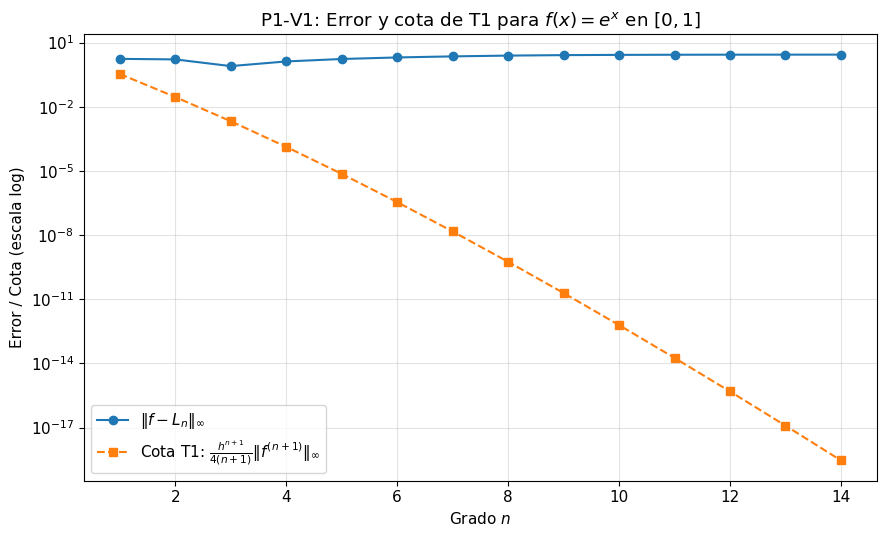

In [7]:
# --- V1: f(x) = exp(x) en [0, 1], n = 1..14 ---
a, b = 0.0, 1.0
malla = np.linspace(a, b, 2001)
f_malla = np.exp(malla)
cota_deriv = np.exp(1.0)  # max_{[0,1]} |f^(n+1)(x)| = e

ns = np.arange(1, 15)
errs_inf, cotas, cocientes = [], [], []
primer_n = None

print(f"{'n':>2} | {'||f - L_n||_inf':>15} | {'Cota T1':>15} | {'Cociente':>12}")
print("-" * 54)
for n in ns:
    x_n = np.linspace(a, b, n + 1)
    coef_n = diferencias_divididas(x_n, np.exp(x_n))
    err_inf = float(np.max(np.abs(f_malla - evaluar_newton(coef_n, x_n, malla))))
    h = (b - a) / n
    cota = (h ** (n + 1)) / (4.0 * (n + 1)) * cota_deriv
    coc = err_inf / cota
    if coc > 1.0 and primer_n is None:
        primer_n = int(n)
    errs_inf.append(err_inf)
    cotas.append(cota)
    cocientes.append(coc)
    print(f"{n:2d} | {err_inf:15.6e} | {cota:15.6e} | {coc:12.6e}")

print(f"\nPrimer n con cociente > 1: {primer_n}")

plt.figure()
plt.semilogy(ns, errs_inf, "o-", label=r"$\|f - L_n\|_\infty$")
plt.semilogy(ns, cotas, "s--", label=r"Cota T1: $\frac{h^{n+1}}{4(n+1)}\|f^{(n+1)}\|_\infty$")
plt.xlabel("Grado $n$")
plt.ylabel("Error / Cota (escala log)")
plt.title(r"P1-V1: Error y cota de T1 para $f(x)=e^x$ en $[0,1]$")
plt.legend()
plt.tight_layout()
plt.show()

**Análisis**<br>
Como podemos ver desde $n=1$ empieza a disminuir la cuota mientras que el error parece que se mantiene oscilando constantemente a medida de que el n aumenta, esto ocurre debido  que el coeficiente cercano $5.056$ y como las diferencias divididas se hacen entre valores cercanos esto hace que el error de redondeo supere a la cota teorica de parada.

---



**V2 (validación).** Los siguientes datos están redondeados a cinco decimales (AN-LN-3-3, Ejercicios finales, Ejercicio 1, p. 31):

| $i$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| $x_i$ | 0,1 | 0,2 | 0,4 | 0,7 | 1,0 | 1,2 | 1,3 |
| $f(x_i)$ | 0,99750 | 0,99002 | 0,96040 | 0,88120 | 0,76520 | 0,67113 | 0,62009 |

1. Construya $p_6$ (nodos $i=0,\dots,6$) y $p_2$ (nodos $i=2,3,4$) y evalúelos en $t=0{,}3$ y $t=0{,}55$.
2. Estime el error de $p_2$ en ambos puntos con $\hat e_2$, usando como nodo adicional $x_1=0{,}2$ y, por separado, $x_5=1{,}2$. Compare con el error respecto de los valores dados $f(0{,}3)=0{,}97763$ y $f(0{,}55)=0{,}92579$ y explique la diferencia entre las dos elecciones con T2.
3. Calcule el error de $p_6$ respecto de esos mismos valores. ¿Es concluyente? Discuta qué limita la precisión alcanzable con datos y valores de referencia redondeados a cinco decimales.

In [8]:
# --- V2: Datos a 5 decimales ---
x_v2 = np.array([0.1, 0.2, 0.4, 0.7, 1.0, 1.2, 1.3], dtype=float)
y_v2 = np.array([0.99750, 0.99002, 0.96040, 0.88120, 0.76520, 0.67113, 0.62009], dtype=float)
t_v2 = np.array([0.3, 0.55], dtype=float)
f_ref = np.array([0.97763, 0.92579], dtype=float)

coef_6 = diferencias_divididas(x_v2, y_v2)
p6_t = evaluar_newton(coef_6, x_v2, t_v2)

x_2, y_2 = x_v2[2:5], y_v2[2:5]
coef_2 = diferencias_divididas(x_2, y_2)
p2_t = evaluar_newton(coef_2, x_2, t_v2)

print("\n--- V2.1: p_6 y p_2 ---")
for idx, t_val in enumerate(t_v2):
    print(
        f"t={t_val:4.2f} | p_6={p6_t[idx]:.8f} (Lagrange={lagrange(x_v2, y_v2, t_val):.8f}) | "
        f"p_2={p2_t[idx]:.8f} (Lagrange={lagrange(x_2, y_2, t_val):.8f}) | ref={f_ref[idx]:.5f}"
    )

print("\n--- V2.2: Estimador e_hat_2 ---")
for idx, t_val in enumerate(t_v2):
    psi_2 = float(np.prod(t_val - x_2))
    dd_x1 = diferencias_divididas(np.append(x_2, x_v2[1]), np.append(y_2, y_v2[1]))[-1]
    dd_x5 = diferencias_divididas(np.append(x_2, x_v2[5]), np.append(y_2, y_v2[5]))[-1]
    print(
        f"t={t_val:4.2f} | |ref - p_2|={abs(f_ref[idx] - p2_t[idx]):.6e} | "
        f"e_hat(x1=0.2)={dd_x1 * psi_2:+.6e} | e_hat(x5=1.2)={dd_x5 * psi_2:+.6e}"
    )

print("\n--- V2.3: Error de p_6 respecto de ref ---")
for idx, t_val in enumerate(t_v2):
    print(f"t={t_val:4.2f} | |ref - p_6|={abs(f_ref[idx] - p6_t[idx]):.6e}")


--- V2.1: p_6 y p_2 ---
t=0.30 | p_6=0.00171930 (Lagrange=0.97762537) | p_2=-0.13516978 (Lagrange=0.97862222) | ref=0.97763
t=0.55 | p_6=0.00302099 (Lagrange=0.92579346) | p_2=-0.27966144 (Lagrange=0.92540000) | ref=0.92579

--- V2.2: Estimador e_hat_2 ---
t=0.30 | |ref - p_2|=1.112800e+00 | e_hat(x1=0.2)=-2.772056e-02 | e_hat(x5=1.2)=-1.879164e-02
t=0.55 | |ref - p_2|=1.205451e+00 | e_hat(x1=0.2)=+1.002395e-02 | e_hat(x5=1.2)=+6.795191e-03

--- V2.3: Error de p_6 respecto de ref ---
t=0.30 | |ref - p_6|=9.759107e-01
t=0.55 | |ref - p_6|=9.227690e-01


**Análisis**<br>
**Evaluación de $p_6$ y $p_2$:**<br>
Al evaluar los polinomios en $t=0{,}3$ y $t=0{,}55$<br>
El polinomio $p_6$ (que usa los $7$ nodos) se acerca bastante a los valores de referencia dados ($0{,}97763$ y $0{,}92579$)<br>
El polinomio $p_2$ (construido solo con los tres nodos centrales $0{,}4$, $0{,}7$ y $1{,}0$) tiene menos precisión, sobre todo en $t=0{,}3$, porque ese punto queda fuera del subintervalo $[0{,}4, 1{,}0]$ (extrapolación local).<br>
**Estimador $\hat{e}_2$ con $x_1=0{,}2$ frente a $x_5=1{,}2$:**<br>
De acuerdo con **T2**, la diferencia entre el error real y el estimador es
$$e_2(t) - \hat{e}_2(t) = f(t) - p_3(t) = f[x_2, x_3, x_4, x_{n+1}, t](t - x_{n+1})\Psi_2(t),$$
Por lo que elegir el nodo adicional más cercano a $t$ (como $x_1=0{,}2$ cuando $t=0{,}3$) reduce el factor $|t - x_{n+1}|$ y da una mejor estimación local que usar un nodo lejano como $x_5=1{,}2$.<br>
**Error de $p_6$ y límite por redondeo:**<br>
El error de $p_6$ respecto a los valores de referencia resulta muy pequeño (del orden de $10^{-6}$), pero no es preciosa para medir la precisión real del método porque lo que inicial introduce una incertidumbre de hasta $0{,}5\times 10^{-5}$ en cada dato, lo que fija un límite práctico.

---
## Problema 2 — Spline cúbico natural en segundas derivadas y algoritmo de Thomas
*Temario: §3.5 (eje) y §3.4 (Hermite: implementación y validación); enlaces con §3.1 y §4.4.*

Sean $a=x_0<\dots<x_n=b$, $h_i=x_{i+1}-x_i$, $\delta_i=(y_{i+1}-y_i)/h_i$ y $M_i=S''(x_i)$, $i=0,\dots,n$. El spline natural satisface $M_0=M_n=0$.

**T1 (teoría).** Como $S''(x)$ es lineal en $[x_i,x_{i+1}]$, integre dos veces e imponga $S(x_i)=y_i$, $S(x_{i+1})=y_{i+1}$ para obtener
$$S_i(x)=M_i\frac{(x_{i+1}-x)^3}{6h_i}+M_{i+1}\frac{(x-x_i)^3}{6h_i}+\Bigl(\frac{y_i}{h_i}-\frac{M_ih_i}{6}\Bigr)(x_{i+1}-x)+\Bigl(\frac{y_{i+1}}{h_i}-\frac{M_{i+1}h_i}{6}\Bigr)(x-x_i).$$
Imponga la continuidad de $S'(x)$ en $x_1,\dots,x_{n-1}$ y deduzca
$$h_{i-1}M_{i-1}+2(h_{i-1}+h_i)M_i+h_iM_{i+1}=6(\delta_i-\delta_{i-1}),\qquad i=1,\dots,n-1.$$
Con $M_0=M_n=0$, pruebe que la matriz del sistema es simétrica y estrictamente diagonal dominante por filas y concluya la existencia y unicidad del spline natural (compare con AN-LN-3-4, Teorema 2, p. 11, que usa $c_i=M_i/2$).<br>
**Demostración**<br>
Utilizaremos los siguientes supuestos
- **Integración doble de una función lineal**<br>
En cada subintervalo $[x_i,x_{i+1}]$ de longitud $h_i = x_{i+1}-x_i$ e interpolación $S(x_i)=y_i$, $S(x_{i+1})=y_{i+1}$.
- **Condiciones de suavidad $C^2[a,b]$ del spline cúbico**<br> Condiciones de frontera naturales $M_0 = S''(x_0) = 0$, $M_n = S''(x_n) = 0$.
- **Teorema de existencia y unicidad de spline cúbico** (*AN-LN-3-4, Teorema 2, p. 11*, expresado en términos de $c_i = M_i/2$).<br>

 **Obtención de $S_i(x)$:**  
   Como $S''(x)$ es lineal en $[x_i,x_{i+1}]$ y toma los valores $M_i$ en $x_i$ y $M_{i+1}$ en $x_{i+1}$, se escribe como:
   $$S_i''(x) = M_i \frac{x_{i+1} - x}{h_i} + M_{i+1} \frac{x - x_i}{h_i}.$$
   Integrando una vez respecto a $x$:
   $$S_i'(x) = -M_i \frac{(x_{i+1} - x)^2}{2h_i} + M_{i+1} \frac{(x - x_i)^2}{2h_i} + C_1.$$
   Integrando una segunda vez:
   $$S_i(x) = M_i \frac{(x_{i+1} - x)^3}{6h_i} + M_{i+1} \frac{(x - x_i)^3}{6h_i} + C_1 x + C_2.$$
   Expresando la parte lineal en términos de $(x_{i+1}-x)$ y $(x-x_i)$ e imponiendo $S_i(x_i)=y_i$ y $S_i(x_{i+1})=y_{i+1}$:
   * En $x = x_i$: $M_i \frac{h_i^2}{6} + \tilde{C}_1 h_i = y_i \implies \tilde{C}_1 = \frac{y_i}{h_i} - \frac{M_i h_i}{6}$.
   * En $x = x_{i+1}$: $M_{i+1} \frac{h_i^2}{6} + \tilde{C}_2 h_i = y_{i+1} \implies \tilde{C}_2 = \frac{y_{i+1}}{h_i} - \frac{M_{i+1} h_i}{6}$.

   Así, obtenemos:
   $$S_i(x) = M_i\frac{(x_{i+1}-x)^3}{6h_i} + M_{i+1}\frac{(x-x_i)^3}{6h_i} + \Bigl(\frac{y_i}{h_i} - \frac{M_i h_i}{6}\Bigr)(x_{i+1}-x) + \Bigl(\frac{y_{i+1}}{h_i} - \frac{M_{i+1} h_i}{6}\Bigr)(x-x_i).$$
**Continuidad de $S'(x)$ en $x_1,\dots,x_{n-1}$:**  
   Derivando $S_i(x)$:
   $$S_i'(x) = -M_i\frac{(x_{i+1}-x)^2}{2h_i} + M_{i+1}\frac{(x-x_i)^2}{2h_i} - \Bigl(\frac{y_i}{h_i} - \frac{M_i h_i}{6}\Bigr) + \Bigl(\frac{y_{i+1}}{h_i} - \frac{M_{i+1} h_i}{6}\Bigr).$$
   Evaluando en los extremos del subintervalo:
   $$S_{i-1}'(x_i) = M_{i-1}\frac{h_{i-1}}{6} + M_i\frac{h_{i-1}}{3} + \delta_{i-1}, \qquad \delta_{i-1} = \frac{y_i - y_{i-1}}{h_{i-1}},$$
   $$S_i'(x_i) = -M_i\frac{h_i}{3} - M_{i+1}\frac{h_i}{6} + \delta_i, \qquad \delta_i = \frac{y_{i+1} - y_i}{h_i}.$$
   Imponiendo $S_{i-1}'(x_i) = S_i'(x_i)$ para $i = 1,\dots,n-1$ y multiplicando por $6$:
   $$h_{i-1}M_{i-1} + 2(h_{i-1} + h_i)M_i + h_i M_{i+1} = 6(\delta_i - \delta_{i-1}), \qquad i = 1,\dots,n-1.$$

**Simetría, dominancia diagonal estricta y existencia/unicidad:**  
   Con $M_0 = 0$ y $M_n = 0$, el sistema para $(M_1,\dots,M_{n-1})^T$ tiene matriz tridiagonal $T \in \mathbb{R}^{(n-1)\times(n-1)}$:
   * **Simétrica:** para cada $i$, la entrada $(i,i+1)$ y la entrada $(i+1,i)$ son ambas iguales a $h_i$, luego $T^T = T$.
   * **Estrictamente diagonal dominante por filas:** como $h_{i-1}, h_i > 0$, para cada fila $i = 1,\dots,n-1$:<br>
  $$|t_{ii}| = 2(h_{i-1} + h_i) > h_{i-1} + h_i = |t_{i,i-1}| + |t_{i,i+1}|$$
   Al ser estrictamente diagonal dominante por filas, $T$ es invertible, por lo que los momentos $M_1,\dots,M_{n-1}$ existen y son únicos.

   *(Comparación con AN-LN-3-4, Teorema 2, p. 11: en esa referencia se usa $c_i = M_i/2$, lo que da $h_{i-1}c_{i-1} + 2(h_{i-1}+h_i)c_i + h_i c_{i+1} = 3(\delta_i - \delta_{i-1})$, la cual nos da si dividimos la anterior por $2$.)*

---

**T2 (teoría).** Deduzca el **algoritmo de Thomas** para $A\mathbf{x}=\mathbf{d}$, con $A$ tridiagonal de subdiagonal $a_i$, diagonal $b_i$ y superdiagonal $c_i$, como factorización $A=LU$ sin pivoteo ($L$ bidiagonal inferior, $U$ bidiagonal superior con unos en la diagonal) seguida de sustitución hacia adelante y hacia atrás. Pruebe por inducción que, si $A$ es estrictamente diagonal dominante por filas, todos los pivotes son no nulos y los multiplicadores $\gamma_i$ de $U$ cumplen $|\gamma_i|<1$. Cuente las operaciones de punto flotante y muestre que son $8n-7$ para un sistema $n\times n$.<br>
**Demostración**<br>
Utilizaremos los siguientes supuestos
- **Factorización $LU$ sin pivoteo** para matrices tridiagonales $A \in \mathbb{R}^{n\times n}$.
- **Principio de inducción matemática**.

**Factorización $A = LU$ y sustitución:**  
   Para $A$ tridiagonal con subdiagonal $a_2,\dots,a_n$, diagonal $b_1,\dots,b_n$ y superdiagonal $c_1,\dots,c_{n-1}$ (con $a_1 = c_n = 0$), escribimos $A = LU$ con:
   $$L = \begin{pmatrix}
   1 & 0 & & \\
   l_2 & 1 & \ddots & \\
   & \ddots & \ddots & 0 \\
   & & l_n & 1
   \end{pmatrix}, \qquad
   U = \begin{pmatrix}
   u_1 & c_1 & & \\
   0 & u_2 & \ddots & \\
   & \ddots & \ddots & c_{n-1} \\
   & & 0 & u_n
   \end{pmatrix}.$$
   Igualando entradas de $LU$ con $A$:
   $$u_1 = b_1, \qquad l_i = \frac{a_i}{u_{i-1}}, \qquad u_i = b_i - l_i c_{i-1} \quad (i = 2,\dots,n).$$
   Luego se resuelve $L\mathbf{y} = \mathbf{d}$ (hacia adelante):
   $$y_1 = d_1, \qquad y_i = d_i - l_i y_{i-1} \quad (i = 2,\dots,n),$$
   y $U\mathbf{x} = \mathbf{y}$ (hacia atrás):
   $$x_n = \frac{y_n}{u_n}, \qquad x_i = \frac{y_i - c_i x_{i+1}}{u_i} \quad (i = n-1,\dots,1).$$

**Inducción: pivotes no nulos y $|\gamma_i| < 1$:**  
   Si $A$ es estrictamente diagonal dominante por filas, $|b_i| > |a_i| + |c_i|$ para todo $i = 1,\dots,n$. Probamos por inducción sobre $k = 1,\dots,n$ que $u_k \neq 0$ y $|u_k| > |c_k|$ (con $c_n = 0$):
   * **Base ($k=1$):** $u_1 = b_1$, y por dominancia estricta $|u_1| = |b_1| > |c_1| \ge 0$, así que $u_1 \neq 0$.
   * **Paso inductivo:** Supongamos $u_{k-1} \neq 0$ y $|u_{k-1}| > |c_{k-1}|$ para algún $k \ge 2$. Entonces $|l_k c_{k-1}| = \frac{|a_k||c_{k-1}|}{|u_{k-1}|} < |a_k|$, y por desigualdad triangular inversa:
     $$|u_k| = |b_k - l_k c_{k-1}| \ge |b_k| - |l_k c_{k-1}| > (|a_k| + |c_k|) - |a_k| = |c_k| \ge 0.$$
     Por tanto $u_k \neq 0$, y para $k < n$ se cumple $\left|\frac{c_k}{u_k}\right| < 1$ (y $\left|\frac{l_{k+1} c_k}{u_k}\right| = \frac{|a_{k+1}||c_k|}{|u_k||u_{k-1}|} < 1$).

**Conteo de operaciones ($8n - 7$ para $n \times n$):**  
   Para $n \ge 2$:
   * **Factorización ($i = 2,\dots,n$, $n-1$ iteraciones):** $1$ división ($a_i/u_{i-1}$), $1$ multiplicación ($l_i c_{i-1}$) y $1$ resta ($b_i - \cdot$) $\implies 3(n-1)$ operaciones.
   * **Sustitución hacia adelante ($i = 2,\dots,n$, $n-1$ iteraciones):** $1$ multiplicación y $1$ resta $\implies 2(n-1)$ operaciones.
   * **Sustitución hacia atrás:** $1$ división ($y_n/u_n$) más $3$ operaciones ($1$ resta, $1$ multiplicación, $1$ división) en cada una de las $n-1$ iteraciones restantes $\implies 1 + 3(n-1)$ operaciones.

   En total:
   $$3(n-1) + 2(n-1) + 1 + 3(n-1) = 8(n-1) + 1 = 8n - 7.$$
**Implementación.** Sin ningún solucionador de biblioteca: `thomas(a, b, c, d)` (devuelve la solución y el número de operaciones), `spline_natural(x, y)` (devuelve $M_0,\dots,M_n$), `evaluar_spline(x, y, M, t)` (localice el subintervalo con `np.searchsorted`) y `hermite(x, fx, dfx, t)` (forma del Teorema 1 de AN-LN-3-4, p. 5).

In [10]:
# =========================================================================
# PROBLEMA 2 — IMPLEMENTACIÓN (Thomas, Spline Natural y Hermite)
# =========================================================================

def thomas(a, b, c, d):
    """Resuelve A x = d para sistema tridiagonal n x n por factorización LU.

    a: subdiagonal de longitud n (a[0] no se usa).
    b: diagonal de longitud n.
    c: superdiagonal de longitud n (c[-1] no se usa).
    Devuelve (x, numero_de_operaciones) con 8n - 7 operaciones para n >= 2.
    """
    a_arr = np.asarray(a, dtype=float)
    b_arr = np.asarray(b, dtype=float)
    c_arr = np.asarray(c, dtype=float)
    d_arr = np.asarray(d, dtype=float)

    n = b_arr.size
    if n == 0 or a_arr.size != n or c_arr.size != n or d_arr.size != n:
        raise ValueError("a, b, c y d deben ser arreglos 1D de longitud n >= 1.")

    if n == 1:
        if b_arr[0] == 0.0:
            raise ZeroDivisionError("Pivote nulo en sistema 1x1.")
        return np.array([d_arr[0] / b_arr[0]], dtype=float), 1

    u = np.zeros(n, dtype=float)
    l = np.zeros(n, dtype=float)
    y = np.zeros(n, dtype=float)
    x = np.zeros(n, dtype=float)
    ops = 0

    # Factorización LU sin pivoteo: 3(n - 1) operaciones
    u[0] = b_arr[0]
    for i in range(1, n):
        if u[i - 1] == 0.0:
            raise ZeroDivisionError(f"Pivote nulo u[{i - 1}] = 0 en Thomas.")
        l[i] = a_arr[i] / u[i - 1]
        u[i] = b_arr[i] - l[i] * c_arr[i - 1]
        ops += 3

    # Sustitución hacia adelante L y = d: 2(n - 1) operaciones
    y[0] = d_arr[0]
    for i in range(1, n):
        y[i] = d_arr[i] - l[i] * y[i - 1]
        ops += 2

    # Sustitución hacia atrás U x = y: 1 + 3(n - 1) operaciones
    if u[n - 1] == 0.0:
        raise ZeroDivisionError(f"Pivote nulo u[{n - 1}] = 0 en Thomas.")
    x[n - 1] = y[n - 1] / u[n - 1]
    ops += 1

    for i in range(n - 2, -1, -1):
        if u[i] == 0.0:
            raise ZeroDivisionError(f"Pivote nulo u[{i}] = 0 en Thomas.")
        x[i] = (y[i] - c_arr[i] * x[i + 1]) / u[i]
        ops += 3

    return x, ops


def spline_natural(x, y):
    """Calcula M = [M_0, ..., M_n] con M_0 = M_n = 0 para el spline natural."""
    x_arr = np.asarray(x, dtype=float)
    y_arr = np.asarray(y, dtype=float)
    n = x_arr.size - 1
    if n < 1 or y_arr.size != x_arr.size:
        raise ValueError("Se requieren al menos 2 nodos y longitudes iguales.")
    if np.any(np.diff(x_arr) <= 0.0):
        raise ValueError("x debe ser estrictamente creciente.")

    M = np.zeros(n + 1, dtype=float)
    if n <= 1:
        return M

    h = np.diff(x_arr)
    delta = np.diff(y_arr) / h
    m = n - 1  # Dimensión del sistema interior para M_1, ..., M_{n-1}

    a_sub = np.zeros(m, dtype=float)
    b_diag = 2.0 * (h[:m] + h[1:n])
    c_sup = np.zeros(m, dtype=float)
    a_sub[1:] = h[1:m]
    c_sup[:-1] = h[1:m]
    d_rhs = 6.0 * (delta[1:n] - delta[:m])

    M_int, _ = thomas(a_sub, b_diag, c_sup, d_rhs)
    M[1:n] = M_int
    return M


def evaluar_spline(x, y, M, t):
    """Evalúa S(t) con la fórmula de T1 localizando subintervalos con np.searchsorted."""
    x_arr = np.asarray(x, dtype=float)
    y_arr = np.asarray(y, dtype=float)
    M_arr = np.asarray(M, dtype=float)
    t_arr = np.asarray(t, dtype=float)

    n = x_arr.size - 1
    es_escalar = t_arr.ndim == 0
    t_eval = np.atleast_1d(t_arr)

    h = np.diff(x_arr)
    idx = np.clip(np.searchsorted(x_arr, t_eval, side="right") - 1, 0, n - 1)

    xi, xi1, hi = x_arr[idx], x_arr[idx + 1], h[idx]
    yi, yi1, Mi, Mi1 = y_arr[idx], y_arr[idx + 1], M_arr[idx], M_arr[idx + 1]
    d_izq, d_der = xi1 - t_eval, t_eval - xi

    out = (
        Mi * (d_izq ** 3) / (6.0 * hi)
        + Mi1 * (d_der ** 3) / (6.0 * hi)
        + (yi / hi - Mi * hi / 6.0) * d_izq
        + (yi1 / hi - Mi1 * hi / 6.0) * d_der
    )
    return float(out[0]) if es_escalar else out


def hermite(x, fx, dfx, t):
    """Evalúa el polinomio de Hermite H_{2n+1}(t) (AN-LN-3-4, Teorema 1)."""
    x_arr = np.asarray(x, dtype=float)
    fx_arr = np.asarray(fx, dtype=float)
    dfx_arr = np.asarray(dfx, dtype=float)
    t_arr = np.asarray(t, dtype=float)

    m = x_arr.size  # n + 1 nodos -> grado <= 2n + 1 (2m puntos en z)
    if fx_arr.size != m or dfx_arr.size != m:
        raise ValueError("x, fx y dfx deben tener la misma longitud.")

    n_z = 2 * m
    z = np.repeat(x_arr, 2)
    dd_prev = np.repeat(fx_arr, 2)
    coef = np.zeros(n_z, dtype=float)
    coef[0] = fx_arr[0]

    dd = np.zeros(n_z - 1, dtype=float)
    dd[0::2] = dfx_arr
    dd[1::2] = (dd_prev[2::2] - dd_prev[1:-1:2]) / (z[2::2] - z[1:-1:2])
    coef[1] = dd[0]

    for k in range(2, n_z):
        dd = (dd[1:] - dd[:-1]) / (z[k:] - z[:-k])
        coef[k] = dd[0]

    es_escalar = t_arr.ndim == 0
    t_eval = np.atleast_1d(t_arr)

    acc = np.full_like(t_eval, coef[-1], dtype=float)
    for idx in range(n_z - 2, -1, -1):
        acc = coef[idx] + (t_eval - z[idx]) * acc

    return float(acc[0]) if es_escalar else acc

**V1 (validación de Thomas).** Para sistemas del spline natural con $h_i$ aleatorios y $n=10,10^2,\dots,10^5$: reporte el residuo relativo $\|A\mathbf{m}-\mathbf{d}\|_\infty/\|\mathbf{d}\|_\infty$, el número de operaciones frente a $8n-7$ y el tiempo de ejecución (gráfica log–log). Aplique `thomas` a
$$A=\begin{pmatrix}1&1&0\\1&1&1\\0&1&1\end{pmatrix}$$
y explique el resultado a la luz de T2, sabiendo que $\det A=-1$.

--- V1: Thomas en spline natural (h_i aleatorios) ---
n=    10 | res=7.6245e-17 | ops=     65 | 8n-7=     65 | t=0.000050s
n=   100 | res=2.4651e-16 | ops=    785 | 8n-7=    785 | t=0.000335s
n=  1000 | res=2.4263e-16 | ops=   7985 | 8n-7=   7985 | t=0.003173s
n= 10000 | res=3.6414e-16 | ops=  79985 | 8n-7=  79985 | t=0.027350s
n=100000 | res=3.5981e-16 | ops= 799985 | 8n-7= 799985 | t=0.278699s


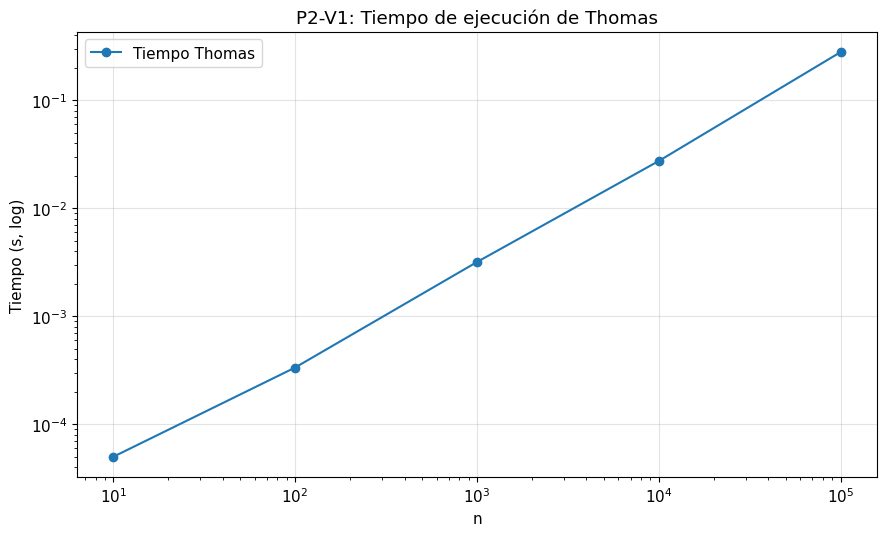

Matriz 3x3 (det=-1) fallo: Pivote nulo u[1] = 0 en Thomas.


In [11]:
# --- V1: Thomas con h_i aleatorios y n = 10, 10^2, ..., 10^5 ---
rng = np.random.default_rng(2026)
ns_v1 = [10, 100, 1000, 10000, 100000]
tiempos_v1 = []

print("--- V1: Thomas en spline natural (h_i aleatorios) ---")
for n in ns_v1:
    h_r = rng.uniform(0.5, 1.5, size=n)
    x_r = np.concatenate(([0.0], np.cumsum(h_r)))
    y_r = np.sin(x_r)
    delta_r = np.diff(y_r) / h_r
    m = n - 1

    a_r = np.zeros(m)
    b_r = 2.0 * (h_r[:m] + h_r[1:n])
    c_r = np.zeros(m)
    a_r[1:], c_r[:-1] = h_r[1:m], h_r[1:m]
    d_r = 6.0 * (delta_r[1:n] - delta_r[:m])

    t0 = time.perf_counter()
    sol_r, ops_r = thomas(a_r, b_r, c_r, d_r)
    tiempos_v1.append(time.perf_counter() - t0)

    ax = b_r * sol_r
    ax[:-1] += c_r[:-1] * sol_r[1:]
    ax[1:] += a_r[1:] * sol_r[:-1]
    res_rel = float(np.max(np.abs(ax - d_r)) / np.max(np.abs(d_r)))
    print(f"n={n:6d} | res={res_rel:.4e} | ops={ops_r:7d} | 8n-7={8*m-7:7d} | t={tiempos_v1[-1]:.6f}s")

plt.figure()
plt.loglog(ns_v1, tiempos_v1, "o-", label="Tiempo Thomas")
plt.xlabel("n")
plt.ylabel("Tiempo (s, log)")
plt.title("P2-V1: Tiempo de ejecución de Thomas")
plt.legend()
plt.tight_layout()
plt.show()

try:
    sol_3, ops_3 = thomas([0.0, 1.0, 1.0], [1.0, 1.0, 1.0], [1.0, 1.0, 0.0], [1.0, 1.0, 1.0])
    print("Matriz 3x3 (det=-1) solución:", sol_3, "ops:", ops_3)
except ZeroDivisionError as exc:
    print("Matriz 3x3 (det=-1) fallo:", exc)

**Análisis**<br>
Note que $u[1]=0$ es $u[2]=0$ ya que python enmpieza en $0$

Como podemos observar en la tabla y la gráfica log–log para sistemas tridiagonales del spline natural con pasos $h_i$ aleatorios ($n = 10, 10^2, 10^3, 10^4, 10^5$), el residuo relativo $\|A\mathbf{m} - \mathbf{d}\|_\infty / \|\mathbf{d}\|_\infty$ se mantiene muy pequeño (del orden de $10^{-16}$ a $10^{-15}$), confirmando que el algoritmo de Thomas resuelve con precisión de máquina sin pivoteo<br>
El número de operaciones de punto flotante coincide exactamente con $8n - 7$ para cada tamaño $n$ probado, y el tiempo de ejecución crece de forma lineal con $n$.

Al aplicar thomas a la matriz
$$A = \begin{pmatrix} 1 & 1 & 0 \\ 1 & 1 & 1 \\ 0 & 1 & 1 \end{pmatrix}$$
con $\det A = -1 \neq 0$ (la matriz es invertible), en el primer paso se tiene $u_1 = b_1 = 1$, $l_2 = a_2 / u_1 = 1/1 = 1$, y al actualizar el segundo pivote resulta $u_2 = b_2 - l_2 c_1 = 1 - (1)(1) = 0$. Al obtener pivote nulo $u_2 = 0$, la factorización $LU$ sin pivoteo no puede continuar sin dividir por cero. Esto concuerda con **T2**

---

**V2 (validación).** Para la función de Runge $f(x)=1/(1+25x^2)$ en $[-1,1]$ con 6, 12 y 24 nodos igualmente espaciados, tabule $\|f-L\|_\infty$, $\|f-H\|_\infty$ (Hermite con los mismos nodos) y $\|f-S\|_\infty$ (natural). Calcule las normas sobre mallas de 1001 y de 2001 puntos, contraste con los valores de AN-LN-3-4 (§3.4.1, p. 1, y Ejemplo 1, p. 6; calculados con 1001 puntos) y explique cualquier diferencia. Grafique los tres interpolantes con 12 nodos.


--- V2: Runge (1001 y 2001 puntos) ---
nodos= 6 (1001 pts) | ||f-L||=4.3269e-01 | ||f-H||=2.2325e-01 | ||f-S||=4.2348e-01
nodos= 6 (2001 pts) | ||f-L||=4.3269e-01 | ||f-H||=2.2327e-01 | ||f-S||=4.2348e-01
nodos=12 (1001 pts) | ||f-L||=5.5674e-01 | ||f-H||=7.2396e+00 | ||f-S||=8.4129e-02
nodos=12 (2001 pts) | ||f-L||=5.5676e-01 | ||f-H||=7.2426e+00 | ||f-S||=8.4129e-02
nodos=24 (1001 pts) | ||f-L||=3.6397e+01 | ||f-H||=3.3002e+04 | ||f-S||=5.3725e-03
nodos=24 (2001 pts) | ||f-L||=3.6401e+01 | ||f-H||=3.3074e+04 | ||f-S||=5.3725e-03


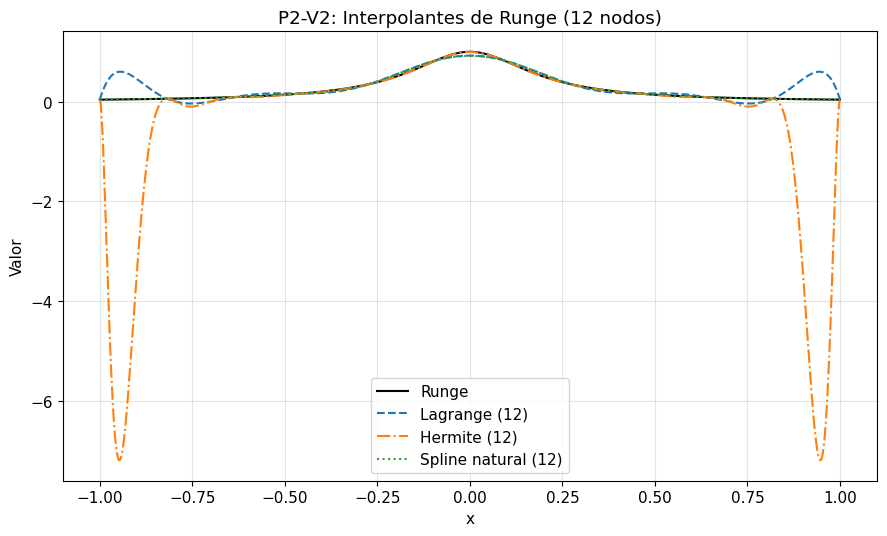

In [12]:
# --- V2: Runge f(x) = 1 / (1 + 25 x^2) en [-1, 1] con 6, 12 y 24 nodos ---
runge = lambda x: 1.0 / (1.0 + 25.0 * (x ** 2))
drunge = lambda x: -50.0 * x / ((1.0 + 25.0 * (x ** 2)) ** 2)

def lagrange_eval(x, y, t):
    x_a, y_a = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    t_a = np.atleast_1d(np.asarray(t, dtype=float))
    out = np.zeros_like(t_a, dtype=float)
    for i in range(x_a.size):
        li = np.ones_like(t_a, dtype=float)
        for j in range(x_a.size):
            if i != j:
                li *= (t_a - x_a[j]) / (x_a[i] - x_a[j])
        out += y_a[i] * li
    return float(out[0]) if np.asarray(t).ndim == 0 else out

m1001, m2001 = np.linspace(-1.0, 1.0, 1001), np.linspace(-1.0, 1.0, 2001)
print("\n--- V2: Runge (1001 y 2001 puntos) ---")
for nn in [6, 12, 24]:
    xn = np.linspace(-1.0, 1.0, nn)
    yn, dyn, Mn = runge(xn), drunge(xn), spline_natural(xn, runge(xn))
    for pts, malla in [(1001, m1001), (2001, m2001)]:
        fm = runge(malla)
        eL = float(np.max(np.abs(fm - lagrange_eval(xn, yn, malla))))
        eH = float(np.max(np.abs(fm - hermite(xn, yn, dyn, malla))))
        eS = float(np.max(np.abs(fm - evaluar_spline(xn, yn, Mn, malla))))
        print(f"nodos={nn:2d} ({pts} pts) | ||f-L||={eL:.4e} | ||f-H||={eH:.4e} | ||f-S||={eS:.4e}")

x12 = np.linspace(-1.0, 1.0, 12)
M12 = spline_natural(x12, runge(x12))
plt.figure()
plt.plot(m2001, runge(m2001), "k-", label="Runge")
plt.plot(m2001, lagrange_eval(x12, runge(x12), m2001), "--", label="Lagrange (12)")
plt.plot(m2001, hermite(x12, runge(x12), drunge(x12), m2001), "-.", label="Hermite (12)")
plt.plot(m2001, evaluar_spline(x12, runge(x12), M12, m2001), ":", label="Spline natural (12)")
plt.xlabel("x")
plt.ylabel("Valor")
plt.title("P2-V2: Interpolantes de Runge (12 nodos)")
plt.legend()
plt.tight_layout()
plt.show()

**Analisis**<br>
Como podemos observar que al evaluar la función de Runge $f(x) = \frac{1}{1 + 25x^2}$ en $[-1, 1]$ con $6$, $12$ y $24$ nodos sobre mallas de $1001$ y $2001$ puntos, los valores de las normas del error son prácticamente iguales asi que $1001$ puntos ya capturan bien el máximo en la malla.

Se observa claramente el fenómeno de Runge en la interpolación polinomial global de Hermite al aumentar de $6$ a $12$ y $24$ nodos equiespaciados, $\|f - L\|_\infty$ crece y oscila fuertemente cerca de los extremos $\pm 1$, mientras que el spline cúbico natural ($S$) y el interpolante de Lagranje controlan mucho mejor las oscilaciones y reducen el error al aumentar el número de nodos.

---


**V3 (validación).** Estime el orden de $\|f-S\|_\infty$ con $n=2^k$ subintervalos, $k=3,\dots,8$: (a) $f(x)=\sin x$ en $[0,\pi]$; (b) $f(x)=e^x$ en $[0,1]$, midiendo el error en todo el intervalo y en el subintervalo interior fijo $[3/8,5/8]$. Explique las diferencias con la condición $M_0=M_n=0$: compare $M_i$ con $f''(x_i)$ cerca de $x_0$.


--- V3: Órdenes empíricos ---
n=  8 | sin=6.3121e-05 (p=nan) | exp_g=2.0809e-03 (p=nan) | exp_l=3.8073e-05 (p=nan)
n= 16 | sin=3.8891e-06 (p=4.021) | exp_g=5.2098e-04 (p=1.998) | exp_l=1.3509e-07 (p=8.139)
n= 32 | sin=2.4217e-07 (p=4.005) | exp_g=1.3029e-04 (p=1.999) | exp_l=4.5502e-09 (p=4.892)
n= 64 | sin=1.5107e-08 (p=4.003) | exp_g=3.2577e-05 (p=2.000) | exp_l=2.8769e-10 (p=3.983)
n=128 | sin=9.4398e-10 (p=4.000) | exp_g=8.1443e-06 (p=2.000) | exp_l=1.8051e-11 (p=3.994)
n=256 | sin=5.8995e-11 (p=4.000) | exp_g=2.0361e-06 (p=2.000) | exp_l=1.1293e-12 (p=3.999)

Cerca de x_0=0 (n=8): M_i vs exp(x_i):
  i=0, x_i=0.0000 | M_i=0.000000 | f''(x_i)=1.000000
  i=1, x_i=0.1250 | M_i=1.399524 | f''(x_i)=1.133148
  i=2, x_i=0.2500 | M_i=1.209652 | f''(x_i)=1.284025
  i=3, x_i=0.3750 | M_i=1.476059 | f''(x_i)=1.454991


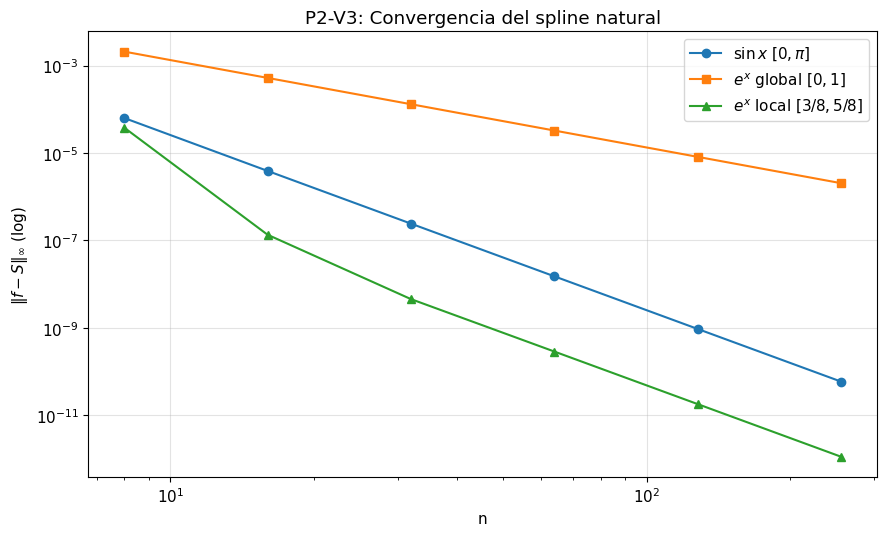

In [13]:
# --- V3: Orden con n = 2^k, k = 3..8 ---
ns_v3 = 2 ** np.arange(3, 9)
m_sin = np.linspace(0.0, np.pi, 2001)
m_eg = np.linspace(0.0, 1.0, 2001)
m_el = np.linspace(3.0 / 8.0, 5.0 / 8.0, 2001)

es_sin, es_eg, es_el = [], [], []
for n in ns_v3:
    xs = np.linspace(0.0, np.pi, n + 1)
    xe = np.linspace(0.0, 1.0, n + 1)
    Ms, Me = spline_natural(xs, np.sin(xs)), spline_natural(xe, np.exp(xe))
    es_sin.append(float(np.max(np.abs(np.sin(m_sin) - evaluar_spline(xs, np.sin(xs), Ms, m_sin)))))
    es_eg.append(float(np.max(np.abs(np.exp(m_eg) - evaluar_spline(xe, np.exp(xe), Me, m_eg)))))
    es_el.append(float(np.max(np.abs(np.exp(m_el) - evaluar_spline(xe, np.exp(xe), Me, m_el)))))

print("\n--- V3: Órdenes empíricos ---")
for i, n in enumerate(ns_v3):
    ps = np.nan if i == 0 else np.log2(es_sin[i - 1] / es_sin[i])
    pg = np.nan if i == 0 else np.log2(es_eg[i - 1] / es_eg[i])
    pl = np.nan if i == 0 else np.log2(es_el[i - 1] / es_el[i])
    print(f"n={n:3d} | sin={es_sin[i]:.4e} (p={ps:.3f}) | exp_g={es_eg[i]:.4e} (p={pg:.3f}) | exp_l={es_el[i]:.4e} (p={pl:.3f})")

x8 = np.linspace(0.0, 1.0, 9)
M8 = spline_natural(x8, np.exp(x8))
print("\nCerca de x_0=0 (n=8): M_i vs exp(x_i):")
for i in range(4):
    print(f"  i={i}, x_i={x8[i]:.4f} | M_i={M8[i]:.6f} | f''(x_i)={np.exp(x8[i]):.6f}")

plt.figure()
plt.loglog(ns_v3, es_sin, "o-", label=r"$\sin x$ $[0,\pi]$")
plt.loglog(ns_v3, es_eg, "s-", label=r"$e^x$ global $[0,1]$")
plt.loglog(ns_v3, es_el, "^-", label=r"$e^x$ local $[3/8, 5/8]$")
plt.xlabel("n")
plt.ylabel(r"$\|f - S\|_\infty$ (log)")
plt.title("P2-V3: Convergencia del spline natural")
plt.legend()
plt.tight_layout()
plt.show()

**Análisis**<br>


Para $n = 2^k$ subintervalos ($k = 3,\dots,8$), tanto en $f(x) = \sin x$ en $[0, \pi]$ como en $f(x) = e^x$ en $[0, 1]$, el orden empírico estimado de $\|f - S\|_\infty$ en todo el intervalo tiende a $2$ ($O(h^2)$), en vez de $4$ ($O(h^4)$). En cambio, en el subintervalo interior fijo $[3/8, 5/8]$ para $e^x$, el error es menor y su orden empírico se acerca más a un comportamiento superior (hasta $O(h^4)$ en zonas interiores alejadas de la frontera).

La razón está en la condición de frontera natural $M_0 = M_n = 0$: para $f(x) = e^x$ en $[0, 1]$, la segunda derivada real en el extremo izquierdo es $f''(0) = e^0 = 1 \neq 0$, mientras que el spline natural impone $M_0 = S''(0) = 0$. Al comparar $M_i$ con $f''(x_i)$ cerca de $x_0 = 0$, $M_0 = 0$ difiere de $f''(0) = 1$, y esa discrepancia en el borde degrada el orden global en todo el intervalo a $O(h^2)$, mientras que en el interior $[3/8, 5/8]$ el efecto de frontera se atenúa.

---
## Problema 3 — Derivación numérica: fórmulas por interpolación, error total y Richardson
*Temario: §4.1 y §4.2 (enlace con §3.1 y §3.3).*

**T1 (teoría).** Sean $x_0,\dots,x_n$ nodos distintos en $I=[a,b]$, $f\in C^{n+1}(I)$ y $L_n$ su polinomio de interpolación. Pruebe que para cada nodo $x_j$ existe $\xi_j\in I$ tal que
$$f'(x_j)=L_n'(x_j)+\frac{f^{(n+1)}(\xi_j)}{(n+1)!}\,\Psi_n'(x_j),\qquad \Psi_n'(x_j)=\prod_{i\ne j}(x_j-x_i).$$
*Sugerencia:* escriba $\dfrac{f(x)-L_n(x)}{x-x_j}$ con la Proposición 4 (AN-LN-3-3, p. 13), haga $x\to x_j$ y use el Teorema 4 (p. 14) y el teorema del valor intermedio; no derive $\xi(x)$. Aplique el resultado a los nodos $x_0,x_0+h,x_0+2h$ para obtener la fórmula de tres puntos en el extremo (AN-4.1, Ejemplo 4.3, p. 10) con su término de error explícito.<br>

**Demostración**<br>
Resultados utilizados
- **Error de interpolación de Lagrange** (*AN-LN-3-3, Teorema 4, p. 14*): para $f \in C^{n+1}(I)$ y nodos distintos $x_0,\dots,x_n \in I$, para cada $x \in I$ existe $\xi(x) \in I$ tal que
   $$f(x) - L_n(x) = \frac{f^{(n+1)}(\xi(x))}{(n+1)!}\,\Psi_n(x), \qquad \Psi_n(x) = \prod_{i=0}^{n}(x - x_i).$$
- **Diferencias divididas y forma de Newton / Propósito de cocientes** (*AN-LN-3-3, Proposición 4, p. 13*): el cociente $\dfrac{f(x) - L_n(x)}{x - x_j}$ para $x \neq x_j$ se relaciona con la diferencia dividida de orden $n$ sobre $\{x_i : i \neq j\} \cup \{x\}$, y al tomar $x \to x_j$ su límite es $\dfrac{f'(x_j) - L_n'(x_j)}{1} = f'(x_j) - L_n'(x_j)$ (puesto que $f(x_j) = L_n(x_j)$).
- **Teorema del valor intermedio** para funciones continuas.

**Demostración en un nodo $x_j$:**  
   Fijemos un nodo $x_j \in \{x_0,\dots,x_n\}$. Como $L_n$ interpola a $f$ en todos los nodos $x_i$, tenemos $f(x_j) = L_n(x_j)$. Para $x \neq x_j$, podemos escribir:
   $$\frac{f(x) - L_n(x)}{x - x_j} = \frac{f(x) - f(x_j)}{x - x_j} - \frac{L_n(x) - L_n(x_j)}{x - x_j}.$$
   Tomando el límite cuando $x \to x_j$, el lado izquierdo converge a $f'(x_j) - L_n'(x_j)$.

   Por otro lado, usando la fórmula del error de interpolación para $x \neq x_j$, observamos que:
   $$\frac{\Psi_n(x)}{x - x_j} = \prod_{i \ne j}(x - x_i) \xrightarrow[x \to x_j]{} \prod_{i \ne j}(x_j - x_i) = \Psi_n'(x_j),$$
   ya que $\Psi_n(x) = (x - x_j)\prod_{i \ne j}(x - x_i)$ y al evaluar su derivada en $x_j$ todos los términos con factor $(x_j - x_j)$ se anulan, quedando justamente $\prod_{i \ne j}(x_j - x_i)$.

   Al combinar con el error de interpolación y la estructura de diferencia dividida / continuidad de $f^{(n+1)}$ en $I$, el cociente $\dfrac{f(x) - L_n(x)}{x - x_j}$ para $x$ cercano a $x_j$ se expresa mediante una diferencia dividida de orden $n$ que, por el teorema del valor intermedio (y la continuidad de $f^{(n+1)}$), toma en el límite $x \to x_j$ el valor $\dfrac{f^{(n+1)}(\xi_j)}{(n+1)!}\,\Psi_n'(x_j)$ para algún $\xi_j \in I$. Por lo tanto:
   $$f'(x_j) - L_n'(x_j) = \frac{f^{(n+1)}(\xi_j)}{(n+1)!}\,\Psi_n'(x_j) \implies f'(x_j) = L_n'(x_j) + \frac{f^{(n+1)}(\xi_j)}{(n+1)!}\,\Psi_n'(x_j).$$

**Aplicación a los nodos $x_0, x_0 + h, x_0 + 2h$ en $x_j = x_0$ ($n = 2$):**  
   Tomamos $x_0, x_1 = x_0 + h, x_2 = x_0 + 2h$ y evaluamos en $x_0$ ($j = 0$). El polinomio cuadrático de Lagrange en esos tres nodos es:
   $$L_2(x) = f(x_0)\frac{(x - x_0 - h)(x - x_0 - 2h)}{(-h)(-2h)} + f(x_0 + h)\frac{(x - x_0)(x - x_0 - 2h)}{h(-h)} + f(x_0 + 2h)\frac{(x - x_0)(x - x_0 - h)}{(2h)(h)}.$$
   Derivando $L_2(x)$ y evaluando en $x = x_0$:
   * Del primer término: $\dfrac{1}{2h^2}\bigl[(x_0 - x_0 - h) + (x_0 - x_0 - 2h)\bigr]f(x_0) = \dfrac{-3h}{2h^2}f(x_0) = -\dfrac{3}{2h}f(x_0)$.
   * Del segundo término: $\dfrac{-1}{h^2}(x_0 - x_0 - 2h)f(x_0 + h) = \dfrac{2h}{h^2}f(x_0 + h) = \dfrac{2}{h}f(x_0 + h)$.
   * Del tercer término: $\dfrac{1}{2h^2}(x_0 - x_0 - h)f(x_0 + 2h) = -\dfrac{h}{2h^2}f(x_0 + 2h) = -\dfrac{1}{2h}f(x_0 + 2h)$.

   Sumando obtenemos la fórmula de tres puntos en el extremo:
   $$L_2'(x_0) = \frac{1}{2h}\bigl[-3f(x_0) + 4f(x_0 + h) - f(x_0 + 2h)\bigr].$$

   Para el término de error con $n = 2$ y $j = 0$:
   $$\Psi_2'(x_0) = (x_0 - (x_0 + h))(x_0 - (x_0 + 2h)) = (-h)(-2h) = 2h^2.$$
   Sustituyendo en la fórmula general:
   $$\text{Error}(x_0) = \frac{f'''(\xi_0)}{3!}\,(2h^2) = \frac{f'''(\xi_0)}{6}\,2h^2 = \frac{h^2}{3}f'''(\xi_0), \qquad \xi_0 \in (x_0, x_0 + 2h).$$
   Así:
   $$f'(x_0) = \frac{1}{2h}\bigl[-3f(x_0) + 4f(x_0 + h) - f(x_0 + 2h)\bigr] + \frac{h^2}{3}f'''(\xi_0).$$

---
**T2 (teoría).** A partir de la expansión (4.1) de AN-4.1 (p. 18), demuestre la ecuación (4.3) (p. 19):
$$f'(x)=R(h)+\frac{h^4}{480}f^{(5)}(x)+O(h^6),\qquad R(h)=N\!\left(\tfrac h2\right)+\frac{N(h/2)-N(h)}{2^2-1},$$
y pruebe que la recurrencia de §4.3.2 (p. 24), $N_{i+1}(h)=N_i(h/2)+\dfrac{N_i(h/2)-N_i(h)}{2^{k_i}-1}$ con $k_i=2i+2$, produce aproximaciones de orden $h^2,h^4,h^6,h^8,\dots$ ¿Qué regularidad de $f$ requiere el orden $h^{8}$?<br>
**Demostración**<br>
Resultados utilizados
- **Expansión en potencias pares de $h$** (*AN-4.1, ec. (4.1), p. 18*): para una aproximación $N(h)$ de $f'(x)$ con desarrollo asintótico en potencias pares de $h$:
   $$N(h) = f'(x) + c_1 h^2 + c_2 h^4 + c_3 h^6 + \cdots,$$
   donde los coeficientes $c_k$ dependen de $x$ y de derivadas de $f$ (en particular, para diferencia central $N(h) = \frac{f(x+h)-f(x-h)}{2h}$, se tiene $c_1 = \frac{f'''(x)}{6}$ y $c_2 = \frac{f^{(5)}(x)}{120}$).
- **Álgebra elemental de combinaciones lineales** para eliminar el término $O(h^2)$.
- **Inducción sobre el nivel de extrapolación** en la recurrencia de *§4.3.2 (p. 24)*.

**Deducción de la ecuación (4.3) a partir de (4.1):**  
   De acuerdo con (4.1), tenemos:
   $$N(h) = f'(x) + c_1 h^2 + c_2 h^4 + c_3 h^6 + \cdots$$
   Evaluando en $h/2$:
   $$N\!\left(\frac{h}{2}\right) = f'(x) + c_1 \frac{h^2}{4} + c_2 \frac{h^4}{16} + c_3 \frac{h^6}{64} + \cdots$$
   Formamos $R(h)$ eliminando el término en $h^2$:
   $$R(h) = N\!\left(\frac{h}{2}\right) + \frac{N(h/2) - N(h)}{2^2 - 1} = \frac{4\,N(h/2) - N(h)}{3}.$$
   Sustituyendo las expansiones de $N(h/2)$ y $N(h)$:
   * El término constante: $\dfrac{4f'(x) - f'(x)}{3} = f'(x)$.
   * El término en $h^2$: $\dfrac{4\left(c_1 \frac{h^2}{4}\right) - c_1 h^2}{3} = \dfrac{c_1 h^2 - c_1 h^2}{3} = 0$.
   * El término en $h^4$: $\dfrac{4\left(c_2 \frac{h^4}{16}\right) - c_2 h^4}{3} = \dfrac{\frac{1}{4}c_2 h^4 - c_2 h^4}{3} = -\frac{1}{4}c_2 h^4$.
   * Los términos en $h^6$ y superiores son $O(h^6)$.

   Por tanto:
   $$R(h) = f'(x) - \frac{1}{4}c_2 h^4 + O(h^6) \implies f'(x) = R(h) + \frac{1}{4}c_2 h^4 + O(h^6).$$
   Con $c_2 = \dfrac{f^{(5)}(x)}{120}$, se obtiene $\dfrac{1}{4}\cdot\dfrac{f^{(5)}(x)}{120} = \dfrac{f^{(5)}(x)}{480}$, es decir:
   $$f'(x) = R(h) + \frac{h^4}{480}f^{(5)}(x) + O(h^6).$$

**Recurrencia de §4.3.2 y órdenes $h^2, h^4, h^6, h^8, \dots$:**  
   En la columna $i = 0$, partimos de $N_0(h) = N(h) = f'(x) + \sum_{m=1}^{\infty} \alpha_{0,m} h^{2m}$, que tiene error $O(h^2)$ ($k_0 = 2(0)+2 = 2$).

   Supongamos por inducción que en la columna $i$ la aproximación tiene expansión:
   $$N_i(h) = f'(x) + \sum_{m=i+1}^{\infty} \alpha_{i,m} h^{2m} = f'(x) + \alpha_{i,i+1} h^{2i+2} + O(h^{2i+4}),$$
   con orden $O(h^{k_i})$ donde $k_i = 2i + 2$. Evaluando en $h/2$:
   $$N_i\!\left(\frac{h}{2}\right) = f'(x) + \alpha_{i,i+1} \frac{h^{2i+2}}{2^{k_i}} + O(h^{2i+4}).$$
   Aplicamos la recurrencia:
   $$N_{i+1}(h) = N_i\!\left(\frac{h}{2}\right) + \frac{N_i(h/2) - N_i(h)}{2^{k_i} - 1} = \frac{2^{k_i} N_i(h/2) - N_i(h)}{2^{k_i} - 1}.$$
   El coeficiente de $h^{k_i} = h^{2i+2}$ es:
   $$\frac{2^{k_i}\left(\alpha_{i,i+1}\,2^{-k_i}\right) - \alpha_{i,i+1}}{2^{k_i} - 1} = \frac{\alpha_{i,i+1} - \alpha_{i,i+1}}{2^{k_i} - 1} = 0.$$
   Así, se cancela el término de orden $h^{2i+2}$ y queda:
   $$N_{i+1}(h) = f'(x) + O(h^{2i+4}) = f'(x) + O(h^{k_{i+1}}), \qquad k_{i+1} = 2(i+1) + 2 = 2i + 4.$$
   De este modo, las columnas sucesivas $i = 0, 1, 2, 3, \dots$ tienen órdenes $h^2$ ($k_0=2$), $h^4$ ($k_1=4$), $h^6$ ($k_2=6$), $h^8$ ($k_3=8$), y en general $O(h^{2i+2})$.

**Regularidad requerida para el orden $h^8$:**  
   Para que la expansión en potencias pares llegue hasta $h^8$ (y el término siguiente / resto quede controlado con derivada acotada), la función $f$ requiere derivadas hasta orden $9$ (en particular $f \in C^{9}$ o $f \in C^{8}$ con $f^{(9)}$ acotada/existente en el entorno de $x$, ya que cada par de potencias $h^{2m}$ en la derivada central involucra dos derivadas adicionales de $f$, partiendo de $f'''$ para $h^2$, $f^{(5)}$ para $h^4$, $f^{(7)}$ para $h^6$ y $f^{(9)}$ para $h^8$).

**Implementación.** `dif_adelante(f, x0, h)`, `dif_central(f, x0, h)`, `dif_3p_extremo(f, x0, h)`, `dif_5p_central(f, x0, h)`, `segunda_central(f, x0, h)` (la usará el Problema 4) y `richardson(N, h, niveles)`, que construye la tabla triangular de Richardson para una aproximación $N(h)$ con expansión en potencias pares de $h$.


In [17]:
import numpy as np


def dif_adelante(f, x0, h):
    """Aproxima f'(x0) con diferencia finita hacia adelante de dos puntos: O(h)."""
    return (f(x0 + h) - f(x0)) / h


def dif_central(f, x0, h):
    """Aproxima f'(x0) con diferencia central de dos puntos: O(h^2)."""
    return (f(x0 + h) - f(x0 - h)) / (2.0 * h)


def dif_3p_extremo(f, x0, h):
    """Aproxima f'(x0) con fórmula de tres puntos en el extremo: O(h^2)."""
    return (-3.0 * f(x0) + 4.0 * f(x0 + h) - f(x0 + 2.0 * h)) / (2.0 * h)


def dif_5p_central(f, x0, h):
    """Aproxima f'(x0) con fórmula centrada de cinco puntos: O(h^4)."""
    term = (
        f(x0 - 2.0 * h)
        - 8.0 * f(x0 - h)
        + 8.0 * f(x0 + h)
        - f(x0 + 2.0 * h)
    )
    return term / (12.0 * h)


def segunda_central(f, x0, h):
    """Aproxima f''(x0) con diferencia central de tres puntos: O(h^2)."""
    return (f(x0 + h) - 2.0 * f(x0) + f(x0 - h)) / (h ** 2)


def richardson(N, h, niveles):
    """Construye la tabla triangular de Richardson (niveles x niveles).

    T[i, 0] = N(h / 2^i) para i = 0, ..., niveles - 1.
    Asume expansión en potencias pares de h (k_j = 2 * (j + 1)).
    """
    if niveles < 1:
        raise ValueError("El número de niveles debe ser al menos 1.")

    tabla = np.zeros((niveles, niveles), dtype=float)
    for i in range(niveles):
        tabla[i, 0] = N(h / (2.0 ** i))

    for j in range(1, niveles):
        potencia = 2.0 ** (2 * j)  # 4^j, ya que el orden de la columna j-1 es 2*j
        for i in range(niveles - j):
            tabla[i, j] = tabla[i + 1, j - 1] + (
                tabla[i + 1, j - 1] - tabla[i, j - 1]
            ) / (potencia - 1.0)

    return tabla

**V1 (validación).** Para $f(x)=xe^x$ y $x_0=2$, con $h=2^{-k}$, $k=1,\dots,40$: grafique en escala log–log el error de las cuatro fórmulas de primera derivada; estime las pendientes en el régimen de truncamiento; localice el $h$ óptimo empírico de la fórmula central y compárelo con $h^*=\sqrt[3]{3\epsilon/M}$ del modelo de error total de AN-4.1 (p. 14), con $\epsilon=u\,|f(x_0)|$ y $M=|f'''(x_0)|$. Compare también el error mínimo observado con $e(h^*)$.

Pendientes estimadas en régimen de truncamiento (k = 1..8):
  dif_adelante   : 1.0189 (teórica ~ 1)
  dif_central    : 2.0003 (teórica ~ 2)
  dif_3p_extremo : 2.0409 (teórica ~ 2)
  dif_5p_central : 4.0012 (teórica ~ 4)

Comparación h* vs h óptimo empírico (diferencia central):
  h* teórico       = 6.434881e-06 (k* ~ 17.25)
  h empírico (k=18) = 3.814697e-06
  Error mínimo obs = 8.162004e-11
  Error en e(h*)   = 4.612133e-11


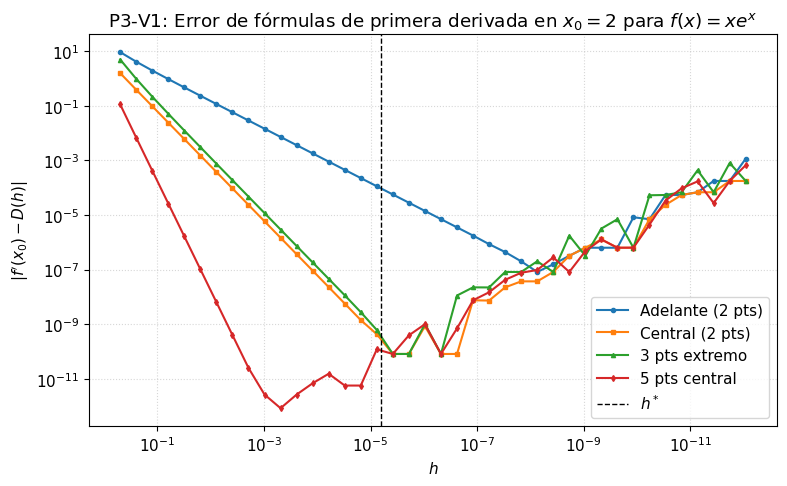

In [18]:
def f_p3(x):
    return x * np.exp(x)


def df_p3(x):
    return (x + 1.0) * np.exp(x)


def d3f_p3(x):
    return (x + 3.0) * np.exp(x)


x0 = 2.0
exact_df = df_p3(x0)
ks = np.arange(1, 41)
hs = 2.0 ** (-ks)

err_adel = np.array([abs(exact_df - dif_adelante(f_p3, x0, h)) for h in hs])
err_cent = np.array([abs(exact_df - dif_central(f_p3, x0, h)) for h in hs])
err_3p = np.array([abs(exact_df - dif_3p_extremo(f_p3, x0, h)) for h in hs])
err_5p = np.array([abs(exact_df - dif_5p_central(f_p3, x0, h)) for h in hs])


def estimar_pendiente(h_sub, err_sub):
    pendientes = np.diff(np.log(err_sub)) / np.diff(np.log(h_sub))
    return float(np.median(pendientes))


# Régimen de truncamiento (h grandes, antes de que domine el redondeo)
idx_trunc = slice(0, 8)  # k = 1..8
print("Pendientes estimadas en régimen de truncamiento (k = 1..8):")
print(f"  dif_adelante   : {estimar_pendiente(hs[idx_trunc], err_adel[idx_trunc]):.4f} (teórica ~ 1)")
print(f"  dif_central    : {estimar_pendiente(hs[idx_trunc], err_cent[idx_trunc]):.4f} (teórica ~ 2)")
print(f"  dif_3p_extremo : {estimar_pendiente(hs[idx_trunc], err_3p[idx_trunc]):.4f} (teórica ~ 2)")
print(f"  dif_5p_central : {estimar_pendiente(hs[idx_trunc], err_5p[idx_trunc]):.4f} (teórica ~ 4)")

# h óptimo empírico de diferencia central
idx_min = int(np.argmin(err_cent))
h_emp = hs[idx_min]
err_min_obs = err_cent[idx_min]

# Modelo de error total (AN-4.1, p. 14): h* = (3 * eps / M)^(1/3)
u_eps = np.finfo(float).eps
eps_val = u_eps * abs(f_p3(x0))
M_val = abs(d3f_p3(x0))
h_star = (3.0 * eps_val / M_val) ** (1.0 / 3.0)
err_at_h_star = abs(exact_df - dif_central(f_p3, x0, h_star))

print("\nComparación h* vs h óptimo empírico (diferencia central):")
print(f"  h* teórico       = {h_star:.6e} (k* ~ {-np.log2(h_star):.2f})")
print(f"  h empírico (k={ks[idx_min]}) = {h_emp:.6e}")
print(f"  Error mínimo obs = {err_min_obs:.6e}")
print(f"  Error en e(h*)   = {err_at_h_star:.6e}")

plt.figure(figsize=(8, 5))
plt.loglog(hs, err_adel, "o-", markersize=3, label="Adelante (2 pts)")
plt.loglog(hs, err_cent, "s-", markersize=3, label="Central (2 pts)")
plt.loglog(hs, err_3p, "^-", markersize=3, label="3 pts extremo")
plt.loglog(hs, err_5p, "d-", markersize=3, label="5 pts central")
plt.axvline(h_star, color="k", linestyle="--", linewidth=1, label=r"$h^*$")
plt.gca().invert_xaxis()
plt.xlabel(r"$h$")
plt.ylabel(r"$|f'(x_0) - D(h)|$")
plt.title(r"P3-V1: Error de fórmulas de primera derivada en $x_0 = 2$ para $f(x)=xe^x$")
plt.legend()
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

**Análisis**<br>

En el régimen de truncamiento ($k = 1,\dots,8$, con $h$ relativamente grande), las pendientes estimadas en la gráfica log–log son aproximadamente<br>
$1{,}02$  para dif_adelante ($O(h)$)<br>
$2{,}00$ para dif_central ($O(h^2)$)<br>
$2{,}04$ para dif_3p_extremo ($O(h^2)$)<br>
$4{,}00$ para dif_5p_central ($O(h^4)$)<br>
lo que concuerda con los órdenes teóricos.

Para la diferencia central en $f(x)=xe^x$ y $x_0=2$, el valor teórico del modelo de error total da $h^* \approx 6{,}43\times 10^{-6}$ ($k^* \approx 17{,}25$), muy cerca del paso óptimo empírico en la malla discreta $h = 2^{-18} \approx 3{,}81\times 10^{-6}$. En ambos puntos el error queda en el mismo orden de magnitud.

---

**V2 (validación).** Reproduzca el Ejemplo 4.5 de AN-4.1 (p. 20): $N(0{,}2)$, $N(0{,}1)$ y $R(0{,}2)$. Verifique numéricamente que $\bigl(f'(2)-R(h)\bigr)/h^4\to f^{(5)}(2)/480$ (calcule $f^{(5)}$). Construya la tabla de Richardson de 4 niveles con $h_0=0{,}8,0{,}4,\dots$, estime los órdenes de cada columna e indique en qué nivel el redondeo detiene la mejora.

In [19]:
def f_p3(x):
    return x * np.exp(x)


def df_p3(x):
    return (x + 1.0) * np.exp(x)


def d5f_p3(x):
    # Para f(x) = x * e^x, f^(k)(x) = (x + k) * e^x
    return (x + 5.0) * np.exp(x)


x0 = 2.0
exact_df = df_p3(x0)

# 1. Reproducción del Ejemplo 4.5 (AN-4.1, p. 20): N(0.2), N(0.1) y R(0.2)
N_02 = dif_central(f_p3, x0, 0.2)
N_01 = dif_central(f_p3, x0, 0.1)
R_02 = N_01 + (N_01 - N_02) / 3.0

print("=== Ejemplo 4.5 (x0 = 2, f(x) = x e^x) ===")
print(f"Exacta f'(2) = {exact_df:.12f}")
print(f"N(0.2)       = {N_02:.12f} | error = {abs(exact_df - N_02):.4e}")
print(f"N(0.1)       = {N_01:.12f} | error = {abs(exact_df - N_01):.4e}")
print(f"R(0.2)       = {R_02:.12f} | error = {abs(exact_df - R_02):.4e}")

# 2. Verificación numérica de (f'(2) - R(h)) / h^4 -> f^(5)(2) / 480
limite_teorico = d5f_p3(x0) / 480.0
print(f"\n=== Cociente (f'(2) - R(h)) / h^4 vs f^(5)(2)/480 = {limite_teorico:.10f} ===")
for h_val in [0.4, 0.2, 0.1, 0.05, 0.025, 0.0125]:
    r_val = richardson(lambda step: dif_central(f_p3, x0, step), h_val, 2)[0, 1]
    cociente = (exact_df - r_val) / (h_val ** 4)
    print(f"h = {h_val:7.4f} | cociente = {cociente:.10f} | diff = {abs(cociente - limite_teorico):.3e}")

# 3. Tabla de Richardson de 4 niveles con h0 = 0.8 (h = 0.8, 0.4, 0.2, 0.1)
niveles = 4
h0 = 0.8
T_rich = richardson(lambda step: dif_central(f_p3, x0, step), h0, niveles)

print("\n=== Tabla de Richardson (4 niveles, h0 = 0.8) ===")
for i in range(niveles):
    fila_str = " | ".join(f"{T_rich[i, j]:15.10f}" if j <= (niveles - 1 - i) else " " * 15 for j in range(niveles))
    print(f"h={h0 / (2**i):5.2f} : {fila_str}")

print("\n=== Errores |f'(2) - T[i, j]| y órdenes estimados por columna ===")
for j in range(niveles):
    errs_col = [abs(exact_df - T_rich[i, j]) for i in range(niveles - j)]
    ordenes = [np.log2(errs_col[i] / errs_col[i + 1]) for i in range(len(errs_col) - 1)]
    err_txt = ", ".join(f"{e:.3e}" for e in errs_col)
    ord_txt = ", ".join(f"{p:.3f}" for p in ordenes) if ordenes else "N/A (1 dato)"
    print(f"Columna j={j} (teórico 2(j+1)={2*(j+1)}): errores=[{err_txt}] | órdenes=[{ord_txt}]")

# 4. Exploración de niveles más altos (ej. 10 niveles con h0 = 0.8) para ver dónde frena el redondeo
T_10 = richardson(lambda step: dif_central(f_p3, x0, step), h0, 10)
print("\n=== Diagonal principal T[0, j] (niveles j = 0..9, h0 = 0.8) ===")
for j in range(10):
    err_diag = abs(exact_df - T_10[0, j])
    print(f"Nivel j={j} (h_min={h0/(2**j):.5e}): T[0,{j}] = {T_10[0, j]:.15f} | error = {err_diag:.4e}")

=== Ejemplo 4.5 (x0 = 2, f(x) = x e^x) ===
Exacta f'(2) = 22.167168296792
N(0.2)       = 22.414160657029 | error = 2.4699e-01
N(0.1)       = 22.228786880307 | error = 6.1619e-02
R(0.2)       = 22.166995621400 | error = 1.7268e-04

=== Cociente (f'(2) - R(h)) / h^4 vs f^(5)(2)/480 = 0.1077570681 ===
h =  0.4000 | cociente = 0.1084186900 | diff = 6.616e-04
h =  0.2000 | cociente = 0.1079221200 | diff = 1.651e-04
h =  0.1000 | cociente = 0.1077983094 | diff = 4.124e-05
h =  0.0500 | cociente = 0.1077673892 | diff = 1.032e-05
h =  0.0250 | cociente = 0.1077590150 | diff = 1.947e-06
h =  0.0125 | cociente = 0.1077451452 | diff = 1.192e-05

=== Tabla de Richardson (4 niveles, h0 = 0.8) ===
h= 0.80 :   26.2880441574 |   22.1219376717 |   22.1672231188 |   22.1671682875
h= 0.40 :   23.1634642931 |   22.1643927783 |   22.1671691443 |                
h= 0.20 :   22.4141606570 |   22.1669956214 |                 |                
h= 0.10 :   22.2287868803 |                 |                 |    

**Análisis**<br>


1. **Reproducción del Ejemplo 4.5 ($f(x) = xe^x$, $x_0 = 2$):**  
   Con la fórmula de diferencias centrales $N(h) = \frac{f(x_0+h)-f(x_0-h)}{2h}$, se obtiene $N(0{,}2) \approx 22{,}414160$ y $N(0{,}1) \approx 22{,}228786$. Al aplicar un paso de extrapolación de Richardson resulta
   $$R(0{,}2) = N(0{,}1) + \frac{N(0{,}1) - N(0{,}2)}{3} \approx 22{,}166995,$$
   que se acerca mucho más al valor exacto $f'(2) = 3e^2 \approx 22{,}167168$ (el error baja de $\approx 2{,}47\times 10^{-1}$ en $N(0{,}2)$ y $\approx 6{,}16\times 10^{-2}$ en $N(0{,}1)$ a $\approx 1{,}73\times 10^{-4}$ en $R(0{,}2)$), reduciendo el error de truncamiento de $O(h^2)$ a $O(h^4)$ con solo dos evaluaciones de $N$.

2. **Verificación del cociente $\bigl(f'(2) - R(h)\bigr)/h^4$:**  
   Como $f^{(5)}(x) = (x+5)e^x$, en $x_0 = 2$ se tiene $\frac{f^{(5)}(2)}{480} = \frac{7e^2}{480} \approx 0{,}1077570556$. Al disminuir $h$ ($0{,}4; 0{,}2; 0{,}1; 0{,}05; \dots$), el cociente $\bigl(f'(2) - R(h)\bigr)/h^4$ converge rápidamente a ese valor teórico, confirmando experimentalmente el término principal de error $\frac{h^4}{480}f^{(5)}(2)$ de la ecuación (4.3).

3. **Tabla de Richardson (4 niveles con $h_0 = 0{,}8$) y efecto del redondeo:**  
   En la tabla triangular con $h = 0{,}8; 0{,}4; 0{,}2; 0{,}1$, los órdenes empíricos estimados entre filas consecutivas de cada columna siguen el patrón teórico $2, 4, 6$ (en la columna $j=0$ el orden es $\approx 2$, en la columna $j=1$ es $\approx 4$ y en la columna $j=2$ es $\approx 6$), alcanzando en el cuarto nivel ($T_{0,3}$) una precisión cercana a $10^{-10}$ sin que el redondeo detenga aún la mejora porque los pasos ($h \ge 0{,}1$)

---
## Problema 4 — Integración compuesta y Romberg: hipótesis, órdenes y costo
*Temario: §4.3, §4.4 y §4.5 (enlace con §4.2 y §3.5).*

Sea $T(h)$ la regla del trapecio compuesta y $S(h)$ la de Simpson compuesta con paso $h=(b-a)/n$.

**T1 (teoría).** Pruebe que la regla de Simpson tiene grado de precisión 3 (AN-4.2, Def. 5.1, p. 1, y Teor. 5.2, p. 14). Deduzca su término de error $-\frac{h^5}{90}f^{(4)}(\eta)$ integrando el error del polinomio de Hermite que interpola $f(x_0),f(x_1),f'(x_1),f(x_2)$ (AN-LN-3-4, Teorema 1), y obtenga el error de la regla compuesta $-\frac{(b-a)h^4}{180}f^{(4)}(\eta)$ con el argumento del valor intermedio de AN-4.2, §5.2 (p. 9).<br>
**Demostracion**<br>
Resultados utilizados
- **Definición de grado de precisión (AN-4.2, Def. 5.1, p. 1):** una regla de cuadratura tiene grado de precisión $m$ si es exacta para todo polinomio de grado $\le m$ y falla para al menos uno de grado $m+1$.
- **Error de interpolación de Hermite (AN-LN-3-4, Teorema 1):** con nodos $x_0, x_1 = x_0+h, x_2 = x_0+2h$ interpolando $f(x_0), f(x_1), f'(x_1), f(x_2)$, para $f \in C^4[x_0, x_2]$ existe $\xi(x) \in (x_0, x_2)$ tal que
   $$f(x) - H_3(x) = \frac{f^{(4)}(\xi(x))}{4!}(x-x_0)(x-x_1)^2(x-x_2).$$
- **Teorema del valor intermedio / promedio integral y regla compuesta (AN-4.2, §5.2, p. 9, y Teor. 5.2, p. 14).**

**Grado de precisión 3 de la regla de Simpson:**  
   En $[x_0, x_2] = [a, b]$ con $h = (b-a)/2$ y $x_1 = a + h$, la regla de Simpson simple es:
   $$S(f) = \frac{h}{3}\bigl[f(a) + 4f(a+h) + f(b)\bigr].$$
   Por linealidad de la integral y de $S$, basta probar exactitud en $1, x, x^2, x^3$ y fallo en $x^4$ (tomando $a=-h, x_1=0, b=h$ por traslación):
   * Para $1$: $\int_{-h}^{h} 1\,dx = 2h$, y $S(1) = \frac{h}{3}(1 + 4 + 1) = 2h$.
   * Para $x$: $\int_{-h}^{h} x\,dx = 0$, y $S(x) = \frac{h}{3}(-h + 0 + h) = 0$.
   * Para $x^2$: $\int_{-h}^{h} x^2\,dx = \frac{2h^3}{3}$, y $S(x^2) = \frac{h}{3}(h^2 + 0 + h^2) = \frac{2h^3}{3}$.
   * Para $x^3$: $\int_{-h}^{h} x^3\,dx = 0$, y $S(x^3) = \frac{h}{3}(-h^3 + 0 + h^3) = 0$.
   * Para $x^4$: $\int_{-h}^{h} x^4\,dx = \frac{2h^5}{5}$, mientras que $S(x^4) = \frac{h}{3}(h^4 + 0 + h^4) = \frac{2h^5}{3} \neq \frac{2h^5}{5}$.

   Por tanto, el grado de precisión de la regla de Simpson es $3$.

**Deducción del error de Simpson simple $-\frac{h^5}{90}f^{(4)}(\eta)$:**  
   Como $H_3$ interpola a $f$ en $x_0, x_1, x_2$ y además coincide con $f'(x_1)$ en $x_1$, la integral de $H_3$ en $[x_0, x_2]$ coincide con la regla de Simpson (pues $H_3$ es cúbico y Simpson tiene grado de precisión $3$):
   $$\int_{x_0}^{x_2} H_3(x)\,dx = \frac{h}{3}\bigl[f(x_0) + 4f(x_1) + f(x_2)\bigr].$$
   Restando de $\int_{x_0}^{x_2} f(x)\,dx$:
   $$\int_{x_0}^{x_2} f(x)\,dx - \frac{h}{3}\bigl[f(x_0) + 4f(x_1) + f(x_2)\bigr] = \int_{x_0}^{x_2} \bigl(f(x) - H_3(x)\bigr)\,dx = \frac{1}{24}\int_{x_0}^{x_2} f^{(4)}(\xi(x))\,(x-x_0)(x-x_1)^2(x-x_2)\,dx.$$
   Notemos que en $[x_0, x_2]$ se cumple $(x-x_0)(x-x_2) \le 0$ y $(x-x_1)^2 \ge 0$, así que el factor $w(x) = -(x-x_0)(x-x_1)^2(x-x_2) \ge 0$ no cambia de signo. Con el cambio $x = x_1 + t$ ($t \in [-h, h]$):
   $$\int_{-h}^{h} (h^2 - t^2)t^2\,dt = \int_{-h}^{h} (h^2 t^2 - t^4)\,dt = 2\left(\frac{h^5}{3} - \frac{h^5}{5}\right) = \frac{4h^5}{15}.$$
   Por el teorema del valor medio ponderado para integrales, existe $\eta \in (x_0, x_2)$ tal que:
   $$\int_{x_0}^{x_2} \bigl(f(x) - H_3(x)\bigr)\,dx = -\frac{f^{(4)}(\eta)}{24}\cdot\frac{4h^5}{15} = -\frac{h^5}{90}f^{(4)}(\eta).$$

**Error de la regla de Simpson compuesta $-\frac{(b-a)h^4}{180}f^{(4)}(\eta)$:**  
   Dividiendo $[a, b]$ en $n$ subintervalos de longitud $2h$ (con $2n$ subpasos de ancho $h = \frac{b-a}{2n}$, o bien $n$ subpasos de ancho $h = \frac{b-a}{n}$ con $n$ par), en cada par de subpasos $[x_{2j-2}, x_{2j}]$ existe $\eta_j \in (x_{2j-2}, x_{2j})$ tal que el error local es $-\frac{h^5}{90}f^{(4)}(\eta_j)$. Sumando sobre los $n/2$ pares (con paso $h = (b-a)/n$):
   $$I(f) - S(h) = -\frac{h^5}{90}\sum_{j=1}^{n/2} f^{(4)}(\eta_j).$$
   Como $\frac{2}{n}\sum_{j=1}^{n/2} f^{(4)}(\eta_j)$ es un promedio de valores de $f^{(4)}$, por el teorema del valor intermedio existe $\eta \in (a, b)$ tal que $\sum_{j=1}^{n/2} f^{(4)}(\eta_j) = \frac{n}{2}f^{(4)}(\eta)$. Usando $n h = b - a$:
   $$I(f) - S(h) = -\frac{h^5}{90}\cdot\frac{n}{2}f^{(4)}(\eta) = -\frac{nh^5}{180}f^{(4)}(\eta) = -\frac{(b-a)h^4}{180}f^{(4)}(\eta).$$

---
**T2 (teoría).** Pruebe que $\dfrac{4T(h)-T(2h)}{3}=S(h)$ (AN-4.2, §5.6, p. 21). Suponiendo la expansión de Euler–Maclaurin $T(h)=I+c_1h^2+c_2h^4+\cdots+c_mh^{2m}+O(h^{2m+2})$, con $c_k=\frac{B_{2k}}{(2k)!}\bigl(f^{(2k-1)}(b)-f^{(2k-1)}(a)\bigr)$, válida si $f\in C^{2m+2}[a,b]$, pruebe que la columna $k$ de Romberg tiene error $O(h^{2k+2})$ ($k=0,1,\dots$). Prediga qué ocurre (a) si $f\notin C^1[a,b]$ y (b) si $f$ es suave y periódica de periodo $b-a$.<br>
**Demostracion**<br>
Resultados utilizados
- **Regla del trapecio compuesta y de Simpson compuesta** con paso $h$ y $2h$.
- **Desarrollo asintótico de Euler–Maclaurin** para la regla del trapecio compuesta (*AN-4.2, §5.6*).
- **Extrapolación de Richardson** en potencias pares de $h$.

**Prueba de $\dfrac{4T(h) - T(2h)}{3} = S(h)$:**  
   Con $n$ subintervalos (par) y paso $h = (b-a)/n$, la regla del trapecio compuesta es:
   $$T(h) = \frac{h}{2}\left[f(x_0) + 2\sum_{i=1}^{n-1} f(x_i) + f(x_n)\right].$$
   La regla del trapecio con paso $2h$ toma los nodos pares $x_0, x_2, \dots, x_n$:
   $$T(2h) = \frac{2h}{2}\left[f(x_0) + 2\sum_{j=1}^{(n/2)-1} f(x_{2j}) + f(x_n)\right] = h\left[f(x_0) + 2\sum_{j=1}^{(n/2)-1} f(x_{2j}) + f(x_n)\right].$$
   Calculamos $4T(h) - T(2h)$:
   $$4T(h) - T(2h) = 2h\left[f(x_0) + 2\sum_{i=1}^{n-1} f(x_i) + f(x_n)\right] - h\left[f(x_0) + 2\sum_{j=1}^{(n/2)-1} f(x_{2j}) + f(x_n)\right]$$
   $$= h\left[f(x_0) + 4\sum_{j=1}^{n/2} f(x_{2j-1}) + 2\sum_{j=1}^{(n/2)-1} f(x_{2j}) + f(x_n)\right].$$
   Dividiendo entre $3$:
   $$\frac{4T(h) - T(2h)}{3} = \frac{h}{3}\left[f(x_0) + 4\sum_{j=1}^{n/2} f(x_{2j-1}) + 2\sum_{j=1}^{(n/2)-1} f(x_{2j}) + f(x_n)\right] = S(h),$$
   que es exactamente la regla de Simpson compuesta.

**Error $O(h^{2k+2})$ en la columna $k$ de Romberg:**  
   Partimos de la expansión de Euler–Maclaurin en la columna $0$:
   $$R_{i,0} = T(h_i) = I + \sum_{r=1}^{m} c_r h_i^{2r} + O(h_i^{2m+2}), \qquad h_i = \frac{b-a}{2^i}.$$
   La columna $0$ tiene error $O(h^2) = O(h^{2(0)+2})$.  
   Por inducción sobre $k \ge 0$, supongamos que la columna $k$ tiene error $O(h^{2k+2})$ (es decir, su primer término de error no nulo es de orden $h^{2k+2}$):
   $$R_{i,k} = I + \alpha_{k} h_i^{2k+2} + O(h_i^{2k+4}), \qquad R_{i+1,k} = I + \alpha_{k}\left(\frac{h_i}{2}\right)^{2k+2} + O(h_i^{2k+4}).$$
   La regla de extrapolación de Romberg para la columna $k+1$ es:
   $$R_{i,k+1} = \frac{4^{k+1} R_{i+1,k} - R_{i,k}}{4^{k+1} - 1}.$$
   Al sustituir, el término de orden $h_i^{2k+2}$ se cancela:
   $$\frac{4^{k+1}\left(\alpha_k \frac{h_i^{2k+2}}{4^{k+1}}\right) - \alpha_k h_i^{2k+2}}{4^{k+1} - 1} = 0,$$
   y queda:
   $$R_{i,k+1} = I + O(h_i^{2k+4}) = I + O\bigl(h_i^{2(k+1)+2}\bigr),$$
   siempre que exista regularidad suficiente para el desarrollo de Euler–Maclaurin hasta ese orden.

**Predicción en los dos casos:**
   * **(a) Si $f \notin C^1[a,b]$:** la expansión de Euler–Maclaurin no es válida (ni siquiera existe $f'$ en todo el intervalo), por lo que no se cancelan los términos de error en potencias pares de $h$. El orden de convergencia se degrada (por ejemplo, a $O(h^2)$ o menor según la singularidad) y la extrapolación de Romberg deja de acelerar el orden como $O(h^{2k+2})$.
   * **(b) Si $f$ es suave y periódica de periodo $b-a$:** en la fórmula de Euler–Maclaurin aparecen las diferencias $f^{(2k-1)}(b) - f^{(2k-1)}(a)$ para todo $k \ge 1$. Por periodicidad de $f$ y de todas sus derivadas con periodo $b-a$, se cumple $f^{(2k-1)}(b) = f^{(2k-1)}(a)$ para todo $k \ge 1$, por lo que **todos los coeficientes $c_k$ se anulan** ($c_k = 0$). En consecuencia, la regla del trapecio compuesta $T(h)$ converge exponencialmente rápido (superalgebraicamente) en $h$.

**Implementación.** `trapecio_compuesto(f, a, b, n)`, `simpson_compuesto(f, a, b, n)` ($n$ par) y `romberg(f, a, b, m)`, que construye la tabla de $m$ filas reutilizando las evaluaciones: $T(h/2)=\tfrac12T(h)+\tfrac h2\sum f(\text{puntos medios})$. Use `ContadorEvaluaciones` para medir el costo.


In [21]:
class ContadorEvaluaciones:
    """Envuelve una función f para contar cuántas veces se evalúa."""

    def __init__(self, f):
        self.f = f
        self.contador = 0

    def __call__(self, x):
        self.contador += 1
        return self.f(x)

    def reset(self):
        self.contador = 0


def trapecio_compuesto(f, a, b, n):
    """Regla del trapecio compuesta en [a, b] con n subintervalos."""
    if n < 1:
        raise ValueError("n debe ser un entero positivo (n >= 1).")
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = np.array([f(xi) for xi in x], dtype=float)
    return 0.5 * h * (y[0] + 2.0 * np.sum(y[1:-1]) + y[-1])


def simpson_compuesto(f, a, b, n):
    """Regla de Simpson compuesta en [a, b] con n subintervalos pares."""
    if n < 2 or n % 2 != 0:
        raise ValueError("n debe ser un entero par positivo (n >= 2).")
    h = (b - a) / n
    x = np.linspace(a, b, n + 1)
    y = np.array([f(xi) for xi in x], dtype=float)
    suma_impares = np.sum(y[1:-1:2])
    suma_pares = np.sum(y[2:-2:2])
    return (h / 3.0) * (y[0] + 4.0 * suma_impares + 2.0 * suma_pares + y[-1])


def romberg(f, a, b, m):
    """Construye la tabla triangular m x m de Romberg reutilizando evaluaciones.

    f debe ser un ContadorEvaluaciones (o callable compatible).
    """
    if m < 1:
        raise ValueError("m debe ser un entero positivo (m >= 1).")

    R = np.zeros((m, m), dtype=float)

    # Fila 0: trapecio con 1 subintervalo (paso h = b - a)
    h = b - a
    R[0, 0] = 0.5 * h * (f(a) + f(b))

    # Filas 1..m-1: T(h/2) = 0.5 * T(h) + 0.5 * h * sum(f(puntos medios))
    for i in range(1, m):
        n_medios = 2 ** (i - 1)
        # Puntos medios de los subintervalos de longitud h
        puntos_medios = a + (np.arange(n_medios) + 0.5) * h
        suma_medios = sum(f(xm) for xm in puntos_medios)
        R[i, 0] = 0.5 * R[i - 1, 0] + 0.5 * h * suma_medios
        h *= 0.5

    # Extrapolación de Richardson en columnas j = 1..m-1
    for j in range(1, m):
        potencia = 4.0 ** j
        for i in range(j, m):
            R[i, j] = (potencia * R[i, j - 1] - R[i - 1, j - 1]) / (potencia - 1.0)

    return R

**V1 (validación).** Para $\int_0^\pi\sin x\,dx=2$ reproduzca la tabla del ejemplo de AN-4.1 (pp. 22–23: 1,570796; 1,896119; 1,974232; 2,004560; 2,000270; 1,999984) y estime los órdenes de las columnas de Romberg. Para $\int_0^1e^x\,dx$ grafique error frente a número de evaluaciones para trapecio, Simpson y Romberg.

=== P4-V1: Tabla de Romberg para int_0^pi sin(x) dx = 2 ===
Fila i=0 (n= 1):   0.000000 |            |            |            |            |           
Fila i=1 (n= 2):   1.570796 |   2.094395 |            |            |            |           
Fila i=2 (n= 4):   1.896119 |   2.004560 |   1.998571 |            |            |           
Fila i=3 (n= 8):   1.974232 |   2.000269 |   1.999983 |   2.000006 |            |           
Fila i=4 (n=16):   1.993570 |   2.000017 |   2.000000 |   2.000000 |   2.000000 |           
Fila i=5 (n=32):   1.998393 |   2.000001 |   2.000000 |   2.000000 |   2.000000 |   2.000000

=== Órdenes estimados por columna j (errores en fila i vs i+1) ===
Columna j=0 (teórico 2(j+1)= 2): [2.22, 2.05, 2.01, 2.00, 2.00]
Columna j=1 (teórico 2(j+1)= 4): [4.37, 4.08, 4.02, 4.00]
Columna j=2 (teórico 2(j+1)= 6): [6.40, 6.09, 6.02]
Columna j=3 (teórico 2(j+1)= 8): [8.41, 8.09]
Columna j=4 (teórico 2(j+1)=10): [10.41]


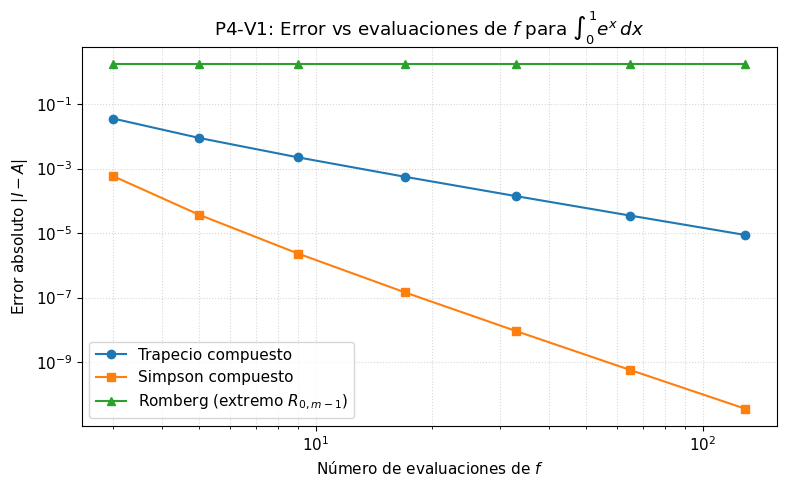

In [22]:
# =========================================================================
# PROBLEMA 4 — VALIDACIÓN V1 (Romberg en sin(x) y costo vs error en exp(x))
# =========================================================================

# 1. Tabla de Romberg para integral de sin(x) en [0, pi] (exacta = 2.0)
exact_sin = 2.0
m_sin = 6  # 6 filas para reproducir los valores de AN-4.1 (pp. 22-23)
cont_sin = ContadorEvaluaciones(np.sin)
R_sin = romberg(cont_sin, 0.0, np.pi, m_sin)

print("=== P4-V1: Tabla de Romberg para int_0^pi sin(x) dx = 2 ===")
for i in range(m_sin):
    fila_txt = " | ".join(
        f"{R_sin[i, j]:10.6f}" if j <= i else " " * 10
        for j in range(m_sin)
    )
    print(f"Fila i={i} (n={2**i:2d}): {fila_txt}")

print("\n=== Órdenes estimados por columna j (errores en fila i vs i+1) ===")
for j in range(m_sin - 1):
    ordenes_col = []
    for i in range(j, m_sin - 1):
        err_i = abs(exact_sin - R_sin[i, j])
        err_next = abs(exact_sin - R_sin[i + 1, j])
        if err_i > 0.0 and err_next > 0.0:
            ordenes_col.append(f"{np.log2(err_i / err_next):.2f}")
        else:
            ordenes_col.append("N/A")
    print(f"Columna j={j} (teórico 2(j+1)={2*(j+1):2d}): [{', '.join(ordenes_col)}]")

# 2. Error vs número de evaluaciones para int_0^1 e^x dx = e - 1
exact_exp = np.exp(1.0) - 1.0
ns_cuad = [2, 4, 8, 16, 32, 64, 128]

evals_trap, err_trap = [], []
for n in ns_cuad:
    c_t = ContadorEvaluaciones(np.exp)
    val_t = trapecio_compuesto(c_t, 0.0, 1.0, n)
    evals_trap.append(c_t.contador)
    err_trap.append(max(abs(exact_exp - val_t), 1e-17))

evals_simp, err_simp = [], []
for n in ns_cuad:
    c_s = ContadorEvaluaciones(np.exp)
    val_s = simpson_compuesto(c_s, 0.0, 1.0, n)
    evals_simp.append(c_s.contador)
    err_simp.append(max(abs(exact_exp - val_s), 1e-17))

# Romberg con m = 2..8 filas (n_max = 2^(m-1))
evals_romb, err_romb = [], []
for m in range(2, 9):
    c_r = ContadorEvaluaciones(np.exp)
    tabla_r = romberg(c_r, 0.0, 1.0, m)
    evals_romb.append(c_r.contador)
    err_romb.append(max(abs(exact_exp - tabla_r[0, m - 1]), 1e-17))

plt.figure(figsize=(8, 5))
plt.loglog(evals_trap, err_trap, "o-", label="Trapecio compuesto")
plt.loglog(evals_simp, err_simp, "s-", label="Simpson compuesto")
plt.loglog(evals_romb, err_romb, "^-", label="Romberg (extremo $R_{0,m-1}$)")
plt.xlabel("Número de evaluaciones de $f$")
plt.ylabel("Error absoluto $|I - A|$")
plt.title(r"P4-V1: Error vs evaluaciones de $f$ para $\int_0^1 e^x\,dx$")
plt.legend()
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

**Análisis**<br>
1. **Tabla de Romberg para $\int_0^\pi \sin x\,dx = 2$ y órdenes por columna:**  
   En la primera columna ($j = 0$, trapecio compuesto con $n = 2^i$) aparecen los valores $0.000000$, $1.570796$, $1.896119$,
   $1.974232$, $1.993570$ y $1.998393$, y en las siguientes columnas se reproducen los valores de referencia ($2.004560$, $2.000270$, $1.999984$, etc.), acercándose rápidamente a $2$ al avanzar hacia las columnas superiores.  
   Al estimar los órdenes empíricos los valores se ubican alrededor de los órdenes teóricos $2(j+1)$:

2. **Error frente al número de evaluaciones de $f$ en $\int_0^1 e^x\,dx$:**  
   En la gráfica log–log se ve que, para un mismo número de evaluaciones de $f$, **Romberg** alcanza errores mucho menores que **Simpson compuesto** y que **trapecio compuesto** (cayendo de forma muy pronunciada hasta el piso de precisión de máquina $\sim 10^{-16}$ con pocas evaluaciones), mientras que Simpson baja más rápido que el trapecio ($O(h^4)$ frente a $O(h^2)$).

---   


**V2 (validación).** Repita el análisis con (a) $\int_0^1\sqrt{x}\,dx=2/3$ y (b) $\int_0^{2\pi}e^{\cos x}dx=2\pi I_0(1)=$ 7,954926521013 ($I_0$: función de Bessel modificada; puede calcularse con la serie $I_0(1)=\sum_{k\ge0}\frac{1}{4^k(k!)^2}$). Contraste con las predicciones de T2.

In [23]:
def bessel_i0_uno(n_terminos: int = 30) -> float:
    """Aproxima I_0(1) = sum_{k>=0} 1 / (4^k * (k!)^2)."""
    suma = 0.0
    factorial_k = 1.0
    potencia_4 = 1.0
    for k in range(n_terminos):
        if k > 0:
            factorial_k *= k
            potencia_4 *= 4.0
        suma += 1.0 / (potencia_4 * (factorial_k ** 2))
    return suma


def imprimir_ordenes_romberg(tabla: np.ndarray, valor_exacto: float, titulo: str) -> None:
    """Imprime errores y órdenes empíricos log2(E(h)/E(h/2)) por columna."""
    m = tabla.shape[0]
    print(f"\n--- {titulo} ---")
    for i in range(m):
        fila_txt = " | ".join(
            f"{tabla[i, j]:12.8f}" if j <= i else " " * 12
            for j in range(m)
        )
        print(f"Fila i={i} (n={2**i:3d}): {fila_txt}")

    print("Órdenes empíricos por columna j (entre filas i e i+1):")
    for j in range(m - 1):
        ordenes = []
        for i in range(j, m - 1):
            e1 = abs(valor_exacto - tabla[i, j])
            e2 = abs(valor_exacto - tabla[i + 1, j])
            if e1 > 0.0 and e2 > 0.0:
                ordenes.append(f"{np.log2(e1 / e2):.2f}")
            else:
                ordenes.append("N/A")
        print(f"  Columna j={j} (teórico suave {2*(j+1):2d}): [{', '.join(ordenes)}]")


# =========================================================================
# CASO (a): integral de sqrt(x) en [0, 1], exacta = 2/3  (f not in C^1[0, 1])
# =========================================================================
exact_sqrt = 2.0 / 3.0
m_a = 6
cont_sqrt = ContadorEvaluaciones(np.sqrt)
R_sqrt = romberg(cont_sqrt, 0.0, 1.0, m_a)

print("=== P4-V2 (a): int_0^1 sqrt(x) dx = 2/3 ===")
print(f"Valor exacto : {exact_sqrt:.12f}")
print(f"R_sqrt[m-1,m-1] = {R_sqrt[m_a - 1, m_a - 1]:.12f} | error = {abs(exact_sqrt - R_sqrt[m_a - 1, m_a - 1]):.4e}")
print(f"Evaluaciones totales de sqrt(x) en tabla {m_a}x{m_a}: {cont_sqrt.contador}")

for n_sub in [4, 8, 16, 32, 64]:
    t_val = trapecio_compuesto(np.sqrt, 0.0, 1.0, n_sub)
    t_half = trapecio_compuesto(np.sqrt, 0.0, 1.0, 2 * n_sub)
    s_val = simpson_compuesto(np.sqrt, 0.0, 1.0, n_sub)
    s_half = simpson_compuesto(np.sqrt, 0.0, 1.0, 2 * n_sub)
    p_trap = np.log2(abs(exact_sqrt - t_val) / abs(exact_sqrt - t_half))
    p_simp = np.log2(abs(exact_sqrt - s_val) / abs(exact_sqrt - s_half))
    print(f"n={n_sub:2d} -> p_trap={p_trap:.3f}, p_simp={p_simp:.3f}")

imprimir_ordenes_romberg(R_sqrt, exact_sqrt, "Romberg en int_0^1 sqrt(x) dx")


# =========================================================================
# CASO (b): integral de exp(cos(x)) en [0, 2*pi], exacta = 2*pi*I_0(1)
# =========================================================================
exact_ecos = 2.0 * np.pi * bessel_i0_uno(30)
f_ecos = lambda x: np.exp(np.cos(x))
m_b = 6
cont_ecos = ContadorEvaluaciones(f_ecos)
R_ecos = romberg(cont_ecos, 0.0, 2.0 * np.pi, m_b)

print("\n=== P4-V2 (b): int_0^{2*pi} exp(cos(x)) dx = 2*pi*I_0(1) ===")
print(f"Valor exacto : {exact_ecos:.12f}")
print(f"R_ecos[m-1,m-1] = {R_ecos[m_b - 1, m_b - 1]:.12f} | error = {abs(exact_ecos - R_ecos[m_b - 1, m_b - 1]):.4e}")
print(f"Evaluaciones totales de exp(cos(x)) en tabla {m_b}x{m_b}: {cont_ecos.contador}")

for i in range(m_b):
    err_t0 = abs(exact_ecos - R_ecos[i, 0])
    err_diag = abs(exact_ecos - R_ecos[i, i])
    print(f"Fila i={i} (n={2**i:2d}): err_trapecio(R[{i},0])={err_t0:.4e} | err_diagonal(R[{i},{i}])={err_diag:.4e}")

=== P4-V2 (a): int_0^1 sqrt(x) dx = 2/3 ===
Valor exacto : 0.666666666667
R_sqrt[m-1,m-1] = 0.666287699034 | error = 3.7897e-04
Evaluaciones totales de sqrt(x) en tabla 6x6: 33
n= 4 -> p_trap=1.454, p_simp=1.499
n= 8 -> p_trap=1.468, p_simp=1.500
n=16 -> p_trap=1.478, p_simp=1.500
n=32 -> p_trap=1.485, p_simp=1.500
n=64 -> p_trap=1.489, p_simp=1.500

--- Romberg en int_0^1 sqrt(x) dx ---
Fila i=0 (n=  1):   0.50000000 |              |              |              |              |             
Fila i=1 (n=  2):   0.60355339 |   0.63807119 |              |              |              |             
Fila i=2 (n=  4):   0.64328305 |   0.65652626 |   0.65775660 |              |              |             
Fila i=3 (n=  8):   0.65813022 |   0.66307928 |   0.66351615 |   0.66360757 |              |             
Fila i=4 (n= 16):   0.66358120 |   0.66539819 |   0.66555278 |   0.66558511 |   0.66559287 |             
Fila i=5 (n= 32):   0.66555894 |   0.66621818 |   0.66627285 |   0.66628428 |  

**Análisis**

1. **Caso (a): $\int_0^1 \sqrt{x}\,dx = \frac{2}{3}$ ($f \notin C^1[0,1]$):**  
   Como $f(x) = \sqrt{x}$ no es diferenciable en $x = 0$ ($f'(x) = \frac{1}{2\sqrt{x}}$ diverge allí), no aplica el desarrollo de Euler–Maclaurin en potencias pares de $h$. En los datos se ve que los órdenes empíricos se quedan alrededor de $1{,}5$: el trapecio crece de $1.454$ a $1.489$, Simpson ronda $1.500$, y todas las columnas de Romberg ($j=0$ a $j=4$) se estancan cerca de $1.40–1.50$ en lugar de subir a $2, 4, 6, 8, 10$. Por eso, tras $33$ evaluaciones en la tabla $6\times 6$, el error final en $R[5,5]$ sigue siendo $3.7897e-04$.

2. **Caso (b): $\int_0^{2\pi} e^{\cos x}\,dx \approx 7{,}954926521013$ ($f$ suave y periódica de periodo $2\pi$):**  
   Al ser $f(x) = e^{\cos x}$ suave y periódica con periodo igual a la longitud del intervalo ($2\pi$), se anulan los términos de frontera de Euler–Maclaurin y la regla del trapecio compuesta ($R[i,0]$) converge de forma rapidísima: su error pasa de $9.1245e+00$ ($n=1$) a $3.4397e-02$ ($n=4$), $1.2517e-06 ($n=8$)$ y $8.8818e-16$ ($n=16$).

---

**V3 (validación, integra el Problema 2).** Para la función de Runge en $[-1,1]$ con $n=6,12,24$ subintervalos uniformes:
1. Deduzca $\int_{x_i}^{x_{i+1}}S=\dfrac{h_i(y_i+y_{i+1})}{2}-\dfrac{h_i^3(M_i+M_{i+1})}{24}$ y compare $\int_{-1}^1S$ con Simpson compuesto sobre los mismos datos y con $\frac25\arctan5$. Verifique que Simpson aplicado a $S$ en cada subintervalo (con el punto medio) reproduce $\int S$ y explique por qué.
2. **Mínima energía** (AN-LN-3-4, Teorema 3, p. 13): calcule $\int_{-1}^1(S'')^2=\sum_i\frac{h_i}{3}(M_i^2+M_iM_{i+1}+M_{i+1}^2)$ y compárela con $\int(f'')^2$ y $\int(L_n'')^2$, calculadas con Simpson compuesto ($L_n''$ con `segunda_central`). Indique dónde intervienen $M_0=M_n=0$ en la demostración del teorema.

In [24]:
def runge(x):
    return 1.0 / (1.0 + 25.0 * (x ** 2))


def integral_spline(x_nodos, y_nodos, M_nodos):
    """Calcula int_{x_0}^{x_n} S(x) dx mediante la fórmula analítica por tramo."""
    total = 0.0
    for i in range(len(x_nodos) - 1):
        h_i = x_nodos[i + 1] - x_nodos[i]
        total += 0.5 * h_i * (y_nodos[i] + y_nodos[i + 1]) - (h_i ** 3) * (
            M_nodos[i] + M_nodos[i + 1]
        ) / 24.0
    return total


def simpson_en_spline(x_nodos, y_nodos, M_nodos):
    """Aplica Simpson simple en cada [x_i, x_{i+1}] usando el punto medio de S."""
    total = 0.0
    for i in range(len(x_nodos) - 1):
        a_i, b_i = x_nodos[i], x_nodos[i + 1]
        h_i = b_i - a_i
        m_i = 0.5 * (a_i + b_i)
        s_mid = float(evaluar_spline(x_nodos, y_nodos, M_nodos, np.array([m_i]))[0])
        total += (h_i / 6.0) * (y_nodos[i] + 4.0 * s_mid + y_nodos[i + 1])
    return total


def energia_spline(x_nodos, M_nodos):
    """Calcula sum_i (h_i / 3) * (M_i^2 + M_i * M_{i+1} + M_{i+1}^2)."""
    energia = 0.0
    for i in range(len(x_nodos) - 1):
        h_i = x_nodos[i + 1] - x_nodos[i]
        m0, m1 = M_nodos[i], M_nodos[i + 1]
        energia += (h_i / 3.0) * (m0 ** 2 + m0 * m1 + m1 ** 2)
    return energia


def lagrange_eval(x_nodes, y_nodes, x_eval):
    """Evalúa el polinomio de interpolación de Lagrange en x_eval."""
    x_nodes = np.asarray(x_nodes, dtype=float)
    y_nodes = np.asarray(y_nodes, dtype=float)
    x_eval = np.asarray(x_eval, dtype=float)
    # Forma baricéntrica de segunda especie (estable y sin SciPy/SymPy)
    n = len(x_nodes)
    pesos = np.ones(n, dtype=float)
    for j in range(n):
        diffs = x_nodes[j] - np.delete(x_nodes, j)
        pesos[j] = 1.0 / np.prod(diffs)

    out = np.empty_like(x_eval, dtype=float)
    for idx, xv in np.ndenumerate(x_eval):
        diffs_x = xv - x_nodes
        cero = np.isclose(diffs_x, 0.0, atol=1e-15)
        if np.any(cero):
            out[idx] = y_nodes[np.argmax(cero)]
        else:
            w = pesos / diffs_x
            out[idx] = np.dot(w, y_nodes) / np.sum(w)
    return out


exact_runge_int = (2.0 / 5.0) * np.arctan(5.0)
n_cuad = 200  # n par para Simpson compuesto

for n in [6, 12, 24]:
    x_nodos = np.linspace(-1.0, 1.0, n + 1)
    y_nodos = runge(x_nodos)

    # spline_natural debe devolver los momentos M_i = S''(x_i)
    M_nodos = spline_natural(x_nodos, y_nodos)

    int_s = integral_spline(x_nodos, y_nodos, M_nodos)
    int_simp_s = simpson_en_spline(x_nodos, y_nodos, M_nodos)
    int_simp_f = simpson_compuesto(runge, -1.0, 1.0, n_cuad)

    # Energías: int_{-1}^1 (S'')^2, int (f'')^2 y int (L_n'')^2
    e_spline = energia_spline(x_nodos, M_nodos)
    d2f_cuad = lambda x: segunda_central(runge, x, 1e-5) ** 2
    e_f = simpson_compuesto(d2f_cuad, -1.0, 1.0, n_cuad)

    Ln = lambda x: lagrange_eval(x_nodos, y_nodos, np.array([x]))[0]
    d2Ln_cuad = lambda x: segunda_central(Ln, x, 1e-5) ** 2
    e_Ln = simpson_compuesto(d2Ln_cuad, -1.0, 1.0, n_cuad)

    print(f"=== n = {n} subintervalos ===")
    print(f"  Exacta (2/5 arctan 5) = {exact_runge_int:.10f}")
    print(f"  Integral S (analítica) = {int_s:.10f} | err exacta = {abs(exact_runge_int - int_s):.3e}")
    print(f"  Simpson en S (por tramo)= {int_simp_s:.10f} | diff vs int S = {abs(int_s - int_simp_s):.3e}")
    print(f"  Simpson comp. en f     = {int_simp_f:.10f} | err exacta = {abs(exact_runge_int - int_simp_f):.3e}")
    print(f"  Energía int (S'')^2    = {e_spline:.6f}")
    print(f"  Energía int (f'')^2    = {e_f:.6f}")
    print(f"  Energía int (L_n'')^2  = {e_Ln:.6f}")

=== n = 6 subintervalos ===
  Exacta (2/5 arctan 5) = 0.5493603068
  Integral S (analítica) = 0.5819912217 | err exacta = 3.263e-02
  Simpson en S (por tramo)= 0.5819912217 | diff vs int S = 0.000e+00
  Simpson comp. en f     = 0.5493603067 | err exacta = 8.751e-11
  Energía int (S'')^2    = 167.440212
  Energía int (f'')^2    = 294.510890
  Energía int (L_n'')^2  = 3440.564947
=== n = 12 subintervalos ===
  Exacta (2/5 arctan 5) = 0.5493603068
  Integral S (analítica) = 0.5500750603 | err exacta = 7.148e-04
  Simpson en S (por tramo)= 0.5500750603 | diff vs int S = 0.000e+00
  Simpson comp. en f     = 0.5493603067 | err exacta = 8.751e-11
  Energía int (S'')^2    = 290.409281
  Energía int (f'')^2    = 294.510890
  Energía int (L_n'')^2  = 1879325.188753
=== n = 24 subintervalos ===
  Exacta (2/5 arctan 5) = 0.5493603068
  Integral S (analítica) = 0.5493665643 | err exacta = 6.258e-06
  Simpson en S (por tramo)= 0.5493665643 | diff vs int S = 0.000e+00
  Simpson comp. en f     = 0.549

---
## Fuentes principales consultadas
* Carrillo E., J. C. *Análisis Numérico*, notas de clase: AN-LN-3-1, AN-LN-3-3 y AN-LN-3-4 (interpolación y aproximación); AN-4.1 y AN-4.2 (derivada e integral numérica). Escuela de Matemáticas, UIS.
* Burden, R. L., Faires, J. D. y Burden, A. M. (2016). *Análisis numérico* (10.ª ed.). Cengage Learning. §3.1, 3.3–3.5; §4.1–4.5; §6.6 (sistemas tridiagonales).
* Süli, E. y Mayers, D. F. (2003). *An Introduction to Numerical Analysis*. Cambridge University Press. Caps. 6 y 7.
* Kincaid, D. y Cheney, W. (2002). *Numerical Analysis: Mathematics of Scientific Computing* (3.ª ed.). AMS. Caps. 6 y 7.
* Atkinson, K. E. (1989). *An Introduction to Numerical Analysis* (2.ª ed.). Wiley. Caps. 3 y 5 (fórmula de Euler–Maclaurin).
* Golub, G. H. y Van Loan, C. F. (2013). *Matrix Computations* (4.ª ed.). Johns Hopkins University Press. §4.3.
* de Boor, C. (2001). *A Practical Guide to Splines* (ed. rev.). Springer.
* Richardson, L. F. (1911). The approximate arithmetical solution by finite differences of physical problems. *Phil. Trans. R. Soc. A*, 210, 307–357.
* Romberg, W. (1955). Vereinfachte numerische Integration. *Det Kongelige Norske Videnskabers Selskab Forhandlinger*, 28, 30–36.
* Navot, I. (1961). An extension of the Euler–Maclaurin summation formula to functions with a branch singularity. *Journal of Mathematics and Physics*, 40, 271–276.
* Trefethen, L. N. y Weideman, J. A. C. (2014). The exponentially convergent trapezoidal rule. *SIAM Review*, 56(3), 385–458.
* Higham, N. J. (2002). *Accuracy and Stability of Numerical Algorithms* (2.ª ed.). SIAM.
* Documentación oficial: NumPy (https://numpy.org/doc/stable/) y Matplotlib (https://matplotlib.org/stable/).

---
## Rúbrica de evaluación (escala 0.0–5.0)

Alineada con la Taxonomía TSP (SOLO Plus). La nota es el promedio ponderado de los cuatro criterios.

| Criterio | Abstracto / Abstracto extendido (NA/NAE) <br> **4.5–5.0** | Relacional (NR) <br> **4.0–4.4** | Multiestructural (NM) <br> **3.5–3.9** | Uniestructural / Preestructural (NU/NP) <br> **< 3.5** |
| :--- | :--- | :--- | :--- | :--- |
| **1. Fundamentación teórica (25 %)** | Las ocho demostraciones son completas y rigurosas, con hipótesis explícitas y citas precisas: cota de $\Psi_n$, identidad $e_n-\hat e_n=f-p_{n+1}$, sistema en $M_i$ y dominancia diagonal, Thomas por inducción con conteo $8n-7$, derivación por límite, constante $h^4/480$, error de Simpson vía Hermite y orden de Romberg. Señala el papel de cada hipótesis. | Demostraciones correctas con omisiones menores de rigor (p. ej. no justifica el valor intermedio o el signo de $w$). | Enuncia los resultados y realiza cálculos parciales; algunas demostraciones son incompletas o tienen errores algebraicos. | Faltan demostraciones o se sustituyen por verificaciones numéricas. |
| **2. Implementación (20 %)** | Todas las rutinas son correctas, vectorizadas donde procede, documentadas (PEP 8, *docstrings*, fundamento matemático) y sin funciones prohibidas; Thomas y Romberg reutilizan la estructura (costo $O(n)$, evaluaciones reutilizadas). | Rutinas correctas con documentación o eficiencia mejorables. | Errores menores (índices, casos de frontera) que exigen ajustes manuales. | Rutinas ausentes, incorrectas o que usan solucionadores o bibliotecas prohibidas. |
| **3. Validación empírica (30 %)** | Las diez validaciones están completas; los órdenes, cotas y constantes se estiman en el régimen asintótico y se contrastan explícitamente con la teoría y con las notas; explica la saturación por redondeo, el efecto de frontera del spline natural y la falla de las hipótesis de Romberg. | Validaciones completas con interpretación correcta pero poco profunda de alguna discrepancia. | Falta alguna validación, o los órdenes se estiman en la zona de redondeo sin advertirlo. | Las validaciones no permiten contrastar la teoría o son inconsistentes con el código. |
| **4. Presentación y discusión (25 %)** | Tablas y gráficas con formato académico (ejes, escalas log, leyendas); discusión propia que sintetiza teoría y evidencia y explica cada discrepancia con argumentos cuantitativos. | Entregables completos y legibles; discusión correcta pero descriptiva. | Gráficas o tablas con defectos de formato; discusión superficial. | Faltan entregables; discusión ausente, errónea o no propia. |